# LF-Bench

| Part | Content | Main outputs |
|---|---|---|
| 1, 2 | Dataset checks, split files, first- and second-order structure, WHO-guideline counts, SODS | `split_*.csv`, `second_order_structure.png` |
| A | Leakage attribution M0 to M7 over 10 splits | `kaggle_leakage_runs.csv`, `leakage_accuracy.png` |
| B | Reconstruction of four published protocols | `protocol_reconstructions.csv` |
| C | Representation, imputer and imbalance screens; boosting-library screens | `screen_representations.csv`, `screening_heatmaps.png` |
| D | Tuning, all candidates on the locked hold-out, selection, DeLong and McNemar tests | `kaggle_holdout_results.csv` |
| E | ROC curves, Monte-Carlo re-splits, learning curves, permutation test, permutation importance | `selected_model_evaluation.png` |
| F | Key numbers, LaTeX rows, JSON summary | `kaggle_summary.json` |


In [1]:
import os, sys, json, time, warnings, glob, hashlib, platform
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import sklearn

QUICK = False         # True = short test run
SEED = 42             # hold-out split seed
N_JOBS = 4
OUT = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."

N_SEEDS_LEAK = 3 if QUICK else 10     # leakage splits
CV_REPEATS = 1 if QUICK else 2        # 5x2 CV
N_ITER_TUNE = 5 if QUICK else 25      # tuning draws
N_MC = 5 if QUICK else 20             # Monte-Carlo re-splits
N_PERM = 10 if QUICK else 100         # label permutations (Part E)

# True: fixed settings below and the reference stack; False: take them from the screens and the selection rule
FIXED_CONFIG = True
FIXED_CFG = {"LR": ("SODS+SOMF", "none"), "KNN": ("SODS+SOMF", "none"), "SVM": ("SODS", "none"),
                    "QDA": ("SODS", "SMOTE-Tomek"), "MLP": ("SODS+SOMF", "SMOTE-Tomek"),
                    "ET": ("SODS+SOMF", "none"), "RF": ("SODS+SOMF", "none"), "GBDT-sk": ("SODS+SOMF", "none"),
                    "XGBoost": ("SODS+SOMF", "SMOTE-Tomek"), "LightGBM": ("SODS+SOMF", "SMOTE-Tomek"),
                    "CatBoost": ("SODS+SOMF", "RUS")}

def have(mod):
    try:
        __import__(mod)
        return True
    except Exception:
        return False

HAS = {m: have(m) for m in ["xgboost", "lightgbm", "catboost", "imblearn"]}

VERSIONS = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scipy": scipy.__version__, "scikit-learn": sklearn.__version__}
for m in ["xgboost", "lightgbm", "catboost", "imblearn"]:
    if HAS[m]:
        VERSIONS[m] = getattr(sys.modules[m], "__version__", "?")
print("library availability:", HAS)
print("versions:", VERSIONS)
print(f"QUICK = {QUICK} | leakage splits = {N_SEEDS_LEAK} | CV = 5x{CV_REPEATS} | "
      f"tuning draws = {N_ITER_TUNE} | Monte-Carlo splits = {N_MC} | permutations = {N_PERM}")
if QUICK:
    print("QUICK mode: short test run with fewer splits, repeats and permutations.")

library availability: {'xgboost': True, 'lightgbm': True, 'catboost': True, 'imblearn': True}
versions: {'python': '3.13.18', 'numpy': '2.1.3', 'pandas': '2.3.3', 'scipy': '1.16.3', 'scikit-learn': '1.6.1', 'xgboost': '3.4.1', 'lightgbm': '4.6.0', 'catboost': '1.2.10', 'imblearn': '0.14.2'}
QUICK = False | leakage splits = 10 | CV = 5x2 | tuning draws = 25 | Monte-Carlo splits = 20 | permutations = 100


In [2]:
FEATURES = ["ph", "Hardness", "Solids", "Chloramines", "Sulfate", "Conductivity",
            "Organic_carbon", "Trihalomethanes", "Turbidity"]
TARGET = "Potability"

def find_csv():
    """First CSV under /kaggle/input (then the working folder) that has the nine features and the label."""
    patterns = ["/kaggle/input/**/water_potability.csv", "/kaggle/input/**/*[Pp]otab*.csv",
                "**/water_potability.csv", "**/*[Pp]otab*.csv"]
    seen = set()
    for pat in patterns:
        for path in sorted(glob.glob(pat, recursive=True)):
            if path in seen:
                continue
            seen.add(path)
            try:
                cols = set(pd.read_csv(path, nrows=1).columns)
            except Exception:
                continue
            if set(FEATURES + [TARGET]) <= cols:
                return path
    raise FileNotFoundError("water_potability.csv not found. Add the Kaggle dataset "
                            "'adityakadiwal/water-potability' to this notebook with 'Add Input'.")

DATA = find_csv()
print("data:", DATA)
with open(DATA, "rb") as fh:
    DATA_MD5 = hashlib.md5(fh.read()).hexdigest()
print("md5 :", DATA_MD5)

def load():
    df = pd.read_csv(DATA)
    return df, df[FEATURES].to_numpy(float), df[TARGET].to_numpy(int)

df, X_all, y_all = load()

# stop if the file differs from the Kaggle water-potability dataset
EXPECTED = {"rows": 3276, "potable": 1278, "missing ph": 491, "missing Sulfate": 781,
            "missing Trihalomethanes": 162, "rows with a missing value": 1265}
found = {"rows": len(df), "potable": int(df[TARGET].sum()),
         "missing ph": int(df["ph"].isna().sum()),
         "missing Sulfate": int(df["Sulfate"].isna().sum()),
         "missing Trihalomethanes": int(df["Trihalomethanes"].isna().sum()),
         "rows with a missing value": int(df[FEATURES].isna().any(axis=1).sum())}
for k in EXPECTED:
    print(f"  {k:26s} {found[k]:5d}   (expected {EXPECTED[k]})")
assert found == EXPECTED, "This file differs from the Kaggle water-potability dataset."

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, StratifiedKFold, RandomizedSearchCV

def holdout():
    _, X, y = load()
    return train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

def cv_folds(X, y, reps=None):
    reps = CV_REPEATS if reps is None else reps
    return list(RepeatedStratifiedKFold(n_splits=5, n_repeats=reps, random_state=2026).split(X, y))

Xtr, Xte, ytr, yte = holdout()
assert (len(ytr), len(yte), int(yte.sum())) == (2620, 656, 256), "unexpected hold-out split"
print(f"{len(y_all)} samples, {y_all.sum()} potable ({y_all.mean():.1%}) | "
      f"train {len(ytr)} | hold-out {len(yte)} ({yte.sum()} potable)")

data: /kaggle/input/datasets/adityakadiwal/water-potability/water_potability.csv
md5 : a5eeae83d792e40da6c2f9e1eab945fc
  rows                        3276   (expected 3276)
  potable                     1278   (expected 1278)
  missing ph                   491   (expected 491)
  missing Sulfate              781   (expected 781)
  missing Trihalomethanes      162   (expected 162)
  rows with a missing value   1265   (expected 1265)
3276 samples, 1278 potable (39.0%) | train 2620 | hold-out 656 (256 potable)


## Split definitions
Row indices (0-based, in the row order of `water_potability.csv`) of every split used below, written to CSV.

In [3]:
# Hold-out, 5x2 CV, 10 leakage splits, 20 Monte-Carlo splits (M5/M6 split resampled rows)
n_rows = len(y_all)
idx_tr, idx_te = train_test_split(np.arange(n_rows), test_size=0.2, stratify=y_all, random_state=SEED)
assert np.array_equal(X_all[idx_tr], Xtr, equal_nan=True) and np.array_equal(y_all[idx_te], yte)

partition = np.full(n_rows, "train", dtype=object)
partition[idx_te] = "holdout"
pd.DataFrame({"row": np.arange(n_rows), "potability": y_all, "partition": partition}).to_csv(
    f"{OUT}/split_holdout.csv", index=False)

cv_split = pd.DataFrame({"row": idx_tr})
for k, (_, te) in enumerate(cv_folds(Xtr, ytr, reps=2)):
    cv_split.loc[te, f"repeat{k // 5 + 1}_fold"] = k % 5 + 1
cv_split.astype(int).sort_values("row").to_csv(f"{OUT}/split_cv_5x2.csv", index=False)

def split_table(seeds):
    t = pd.DataFrame({"row": np.arange(n_rows)})
    for s in seeds:
        _, te = train_test_split(np.arange(n_rows), test_size=0.2, stratify=y_all, random_state=s)
        col = np.full(n_rows, "train", dtype=object)
        col[te] = "test"
        t[f"seed{s}"] = col
    return t

split_table(range(10)).to_csv(f"{OUT}/split_leakage_10.csv", index=False)
split_table(range(1000, 1020)).to_csv(f"{OUT}/split_montecarlo_20.csv", index=False)
print("written: split_holdout.csv, split_cv_5x2.csv, split_leakage_10.csv, split_montecarlo_20.csv")

written: split_holdout.csv, split_cv_5x2.csv, split_leakage_10.csv, split_montecarlo_20.csv


## Metrics and tests
Wilson intervals for accuracy, 2,000-sample bootstrap intervals for ROC-AUC, F1 and MCC, DeLong's test for paired AUCs, McNemar's exact test for paired errors, the Nadeau-Bengio corrected resampled t-test for paired CV scores, and Holm's correction.

In [4]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, roc_auc_score, average_precision_score,
                             confusion_matrix, roc_curve)

def scores_of(est, X):
    """Positive-class score, preferring predict_proba."""
    if hasattr(est, "predict_proba"):
        return est.predict_proba(X)[:, 1]
    if hasattr(est, "decision_function"):
        return est.decision_function(X)
    return est.predict(X).astype(float)

def all_metrics(y, yhat, s=None):
    m = dict(acc=accuracy_score(y, yhat), bacc=balanced_accuracy_score(y, yhat),
             prec=precision_score(y, yhat, zero_division=0), rec=recall_score(y, yhat, zero_division=0),
             f1=f1_score(y, yhat, zero_division=0), mcc=matthews_corrcoef(y, yhat))
    if s is not None:
        m["auc"] = roc_auc_score(y, s)
        m["ap"] = average_precision_score(y, s)
    return m

def wilson_ci(k, n, z=1.96):
    p = k / n
    d = 1 + z ** 2 / n
    c = p + z ** 2 / (2 * n)
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2))
    return (c - h) / d, (c + h) / d

def _fast_auc(y, s):
    r = stats.rankdata(s)
    n1 = y.sum()
    n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def bootstrap_ci(y, yhat, s, metric="auc", B=2000, seed=0):
    rng = np.random.RandomState(seed)
    n = len(y)
    out = []
    for _ in range(B):
        idx = rng.randint(0, n, n)
        if len(np.unique(y[idx])) < 2:
            continue
        if metric == "auc":
            out.append(_fast_auc(y[idx], s[idx]))
        elif metric == "f1":
            out.append(f1_score(y[idx], yhat[idx], zero_division=0))
        elif metric == "mcc":
            out.append(matthews_corrcoef(y[idx], yhat[idx]))
    return float(np.percentile(out, 2.5)), float(np.percentile(out, 97.5))

def delong_test(y, s1, s2):
    """DeLong's test for two correlated ROC curves. Returns (auc1, auc2, z, p)."""
    y = np.asarray(y)
    pos, neg = y == 1, y == 0
    m, n = pos.sum(), neg.sum()
    def structural(s):
        sp, sn = s[pos], s[neg]
        v01 = np.array([( (sn < x).sum() + 0.5 * (sn == x).sum() ) / n for x in sp])
        v10 = np.array([( (sp > x).sum() + 0.5 * (sp == x).sum() ) / m for x in sn])
        return v01, v10, v01.mean()
    a01, a10, A = structural(np.asarray(s1, float))
    b01, b10, B = structural(np.asarray(s2, float))
    S01 = np.cov(np.vstack([a01, b01]))
    S10 = np.cov(np.vstack([a10, b10]))
    S = S01 / m + S10 / n
    var = S[0, 0] + S[1, 1] - 2 * S[0, 1]
    z = (A - B) / np.sqrt(var) if var > 0 else 0.0
    return A, B, z, 2 * stats.norm.sf(abs(z))

def mcnemar_test(y, p1, p2):
    b = int(((p1 == y) & (p2 != y)).sum())
    c = int(((p1 != y) & (p2 == y)).sum())
    if b + c == 0:
        return b, c, 1.0
    return b, c, float(stats.binomtest(b, b + c, 0.5).pvalue)

def corrected_resampled_ttest(a, b, n_train, n_test):
    """Nadeau & Bengio (2003) corrected resampled t-test for paired CV scores."""
    d = np.asarray(a) - np.asarray(b)
    k = len(d)
    if np.allclose(d, 0):
        return 0.0, 1.0
    var = d.var(ddof=1)
    t = d.mean() / np.sqrt(var * (1 / k + n_test / n_train))
    return float(t), float(2 * stats.t.sf(abs(t), k - 1))

def holm(p):
    """Holm step-down adjustment of a family of p-values."""
    p = np.asarray(p, float)
    adj, running, m = np.empty(len(p)), 0.0, len(p)
    for rank, i in enumerate(np.argsort(p)):
        running = max(running, (m - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj

## SODS, SOMF and MarginalQDA
SODS keeps a feature when its class-wise dispersion (Brown-Forsythe) or one of its class-wise correlations (Fisher z) differs, Bonferroni-corrected. SOMF adds squares and pairwise products of robust z-scores. MarginalQDA scores each sample with the class-conditional Gaussian of its observed features instead of imputing.

In [5]:
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone

class SODSelector(TransformerMixin, BaseEstimator):
    def __init__(self, alpha=0.05, min_features=2):
        self.alpha, self.min_features = alpha, min_features

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y)
        d = X.shape[1]
        p_var = np.ones(d)
        for j in range(d):
            a = X[(y == 0) & ~np.isnan(X[:, j]), j]
            b = X[(y == 1) & ~np.isnan(X[:, j]), j]
            p_var[j] = stats.levene(a, b, center="median").pvalue
        z_pair = np.zeros((d, d))
        for i in range(d):
            for j in range(i + 1, d):
                r, n = [], []
                for c in (0, 1):
                    m = (y == c) & ~np.isnan(X[:, i]) & ~np.isnan(X[:, j])
                    r.append(np.corrcoef(X[m, i], X[m, j])[0, 1])
                    n.append(m.sum())
                z = (np.arctanh(r[0]) - np.arctanh(r[1])) / np.sqrt(1 / (n[0] - 3) + 1 / (n[1] - 3))
                z_pair[i, j] = z_pair[j, i] = abs(z)
        self.z_pair_ = z_pair
        p_pair = 2 * stats.norm.sf(z_pair)
        keep = (p_var < self.alpha / d) | (p_pair < self.alpha / (d * (d - 1) / 2)).any(1)
        if keep.sum() < self.min_features:                      # fallback: strongest evidence
            keep = np.zeros(d, bool)
            keep[np.argsort(p_var)[:self.min_features]] = True
        self.support_ = keep
        return self

    def transform(self, X):
        return np.asarray(X, float)[:, self.support_]

class SecondOrderMoments(TransformerMixin, BaseEstimator):
    def __init__(self, squares=True, products=True):
        self.squares, self.products = squares, products

    def _build(self, X):
        Z = (np.asarray(X, float) - self.center_) / self.scale_
        out = [Z]
        if self.squares:
            out.append(Z ** 2)
        if self.products:
            i, j = np.triu_indices(Z.shape[1], 1)
            out.append(Z[:, i] * Z[:, j])
        return np.hstack(out)

    def fit(self, X, y=None):
        X = np.asarray(X, float)
        self.center_ = np.nanmedian(X, 0)
        q = np.nanpercentile(X, [25, 75], 0)
        self.scale_ = np.where((q[1] - q[0]) > 0, (q[1] - q[0]) / 1.349, 1.0)
        self.fill_ = np.nanmean(self._build(X), 0)
        return self

    def transform(self, X):
        Z = self._build(X)
        return np.where(np.isnan(Z), self.fill_, Z)

class MarginalQDA(ClassifierMixin, BaseEstimator):
    """Gaussian class-conditional classifier that marginalizes missing values (no imputation)."""
    def __init__(self, reg=1e-2, equal_priors=False):
        self.reg, self.equal_priors = reg, equal_priors

    @staticmethod
    def _pairwise_cov(Z, mu):
        d = Z.shape[1]
        S = np.zeros((d, d))
        C = Z - mu
        for i in range(d):
            for j in range(i, d):
                m = ~np.isnan(C[:, i]) & ~np.isnan(C[:, j])
                S[i, j] = S[j, i] = np.mean(C[m, i] * C[m, j]) if m.sum() > 2 else 0.0
        return S

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y)
        self.classes_ = np.unique(y)
        self.mu_, self.cov_, self.logpi_ = [], [], []
        for c in self.classes_:
            Z = X[y == c]
            mu = np.nanmean(Z, 0)
            S = self._pairwise_cov(Z, mu)
            w, V = np.linalg.eigh(S)
            w = np.clip(w, max(w.max(), 1e-12) * 1e-6, None)     # keep it positive definite
            S = V @ np.diag(w) @ V.T + self.reg * np.diag(np.diag(S) + 1e-12)
            self.mu_.append(mu)
            self.cov_.append(S)
            self.logpi_.append(0.0 if self.equal_priors else np.log((y == c).mean()))
        return self

    def predict_proba(self, X):
        X = np.asarray(X, float)
        L = np.zeros((len(X), len(self.classes_)))
        obs = ~np.isnan(X)
        for pat in np.unique(obs, axis=0):
            rows = np.where((obs == pat).all(1))[0]
            idx = np.where(pat)[0]
            if len(idx) == 0:
                L[rows] = np.array(self.logpi_)
                continue
            Xo = X[np.ix_(rows, idx)]
            for k in range(len(self.classes_)):
                mu = self.mu_[k][idx]
                S = self.cov_[k][np.ix_(idx, idx)]
                sign, logdet = np.linalg.slogdet(S)
                D = Xo - mu
                maha = np.einsum("ij,jk,ik->i", D, np.linalg.pinv(S), D)
                L[rows, k] = self.logpi_[k] - 0.5 * (len(idx) * np.log(2 * np.pi) + logdet + maha)
        L -= L.max(1, keepdims=True)
        P = np.exp(L)
        return P / P.sum(1, keepdims=True)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(1)]

## 2. First- and second-order structure
Tests on the seed-42 training partition, then the class-wise correlation and dispersion plots.

In [6]:
d = len(FEATURES)
obs = ~np.isnan(Xtr)

chi_p = [stats.chi2_contingency(pd.crosstab(~obs[:, j], ytr))[1] for j in range(d) if (~obs[:, j]).any()]
welch_p = [stats.ttest_ind(Xtr[(ytr == 0) & obs[:, j], j], Xtr[(ytr == 1) & obs[:, j], j],
                           equal_var=False).pvalue for j in range(d)]
uni_auc = [roc_auc_score(ytr[obs[:, j]], Xtr[obs[:, j], j]) for j in range(d)]
print("First-order structure on the training partition")
print(f"  missingness vs. label, chi-square   min p = {min(chi_p):.3f}")
print(f"  class means, Welch t-test           min p = {min(welch_p):.3f}")
print(f"  univariate ROC-AUC                  {min(uni_auc):.3f} to {max(uni_auc):.3f}")

# WHO limits from the Kaggle dataset page (hardness 300 mg/L), on the full data
WHO_LIMITS = {"ph": (6.5, 8.5), "Hardness": (None, 300), "Solids": (None, 500), "Chloramines": (None, 4),
              "Sulfate": (None, 250), "Conductivity": (None, 400), "Organic_carbon": (None, 2),
              "Trihalomethanes": (None, 80), "Turbidity": (None, 5)}
viol = np.zeros(len(y_all), int)
for j, f in enumerate(FEATURES):
    lo, hi = WHO_LIMITS[f]
    viol += (X_all[:, j] > hi) | ((X_all[:, j] < lo) if lo is not None else False)
print(f"  WHO guidelines: {np.mean(viol >= 1):.0%} of samples break at least one; mean "
      f"{viol[y_all == 0].mean():.2f} (non-potable) vs {viol[y_all == 1].mean():.2f} (potable)")

bf = []
for j, f in enumerate(FEATURES):
    a, b = Xtr[(ytr == 0) & obs[:, j], j], Xtr[(ytr == 1) & obs[:, j], j]
    bf.append(dict(feature=f, sd_ratio=b.std(ddof=1) / a.std(ddof=1),
                   p=stats.levene(a, b, center="median").pvalue))
bf = pd.DataFrame(bf)
bf["bonferroni"] = bf.p < 0.05 / d
print("\nBrown-Forsythe test, sd(y=1) / sd(y=0)")
print(bf.to_string(index=False, formatters={"sd_ratio": "{:.2f}".format, "p": "{:.1e}".format}))
print(f"  {bf.bonferroni.sum()} features differ after Bonferroni")

sods_full = SODSelector().fit(Xtr, ytr)
z_crit = stats.norm.isf(0.05 / (d * (d - 1)))          # Phi^-1(1 - alpha / [d(d-1)])
pairs = sorted(((sods_full.z_pair_[i, j], FEATURES[i], FEATURES[j])
                for i in range(d) for j in range(i + 1, d)), reverse=True)

def corr(i, j, cls=None):
    m = obs[:, i] & obs[:, j]
    if cls is not None:
        m &= ytr == cls
    return np.corrcoef(Xtr[m, i], Xtr[m, j])[0, 1]

print(f"\nFisher z test of class-wise correlations: {sum(z > z_crit for z, _, _ in pairs)}/36 pairs differ")
for z, a, b in pairs[:3]:
    i, j = FEATURES.index(a), FEATURES.index(b)
    print(f"  {a}-{b}: r(y=0) {corr(i, j, 0):+.2f}, r(y=1) {corr(i, j, 1):+.2f}, "
          f"pooled {corr(i, j):+.2f}, |z| = {z:.1f}")

SODS_KEPT = [f for f, k in zip(FEATURES, sods_full.support_) if k]
print(f"\nSODS on the full training partition keeps {len(SODS_KEPT)} features: {SODS_KEPT}")

First-order structure on the training partition
  missingness vs. label, chi-square   min p = 0.158
  class means, Welch t-test           min p = 0.164
  univariate ROC-AUC                  0.494 to 0.511
  WHO guidelines: 100% of samples break at least one; mean 5.07 (non-potable) vs 5.00 (potable)

Brown-Forsythe test, sd(y=1) / sd(y=0)
        feature sd_ratio       p  bonferroni
             ph     0.87 5.4e-06        True
       Hardness     1.16 8.5e-06        True
         Solids     1.07 3.4e-02       False
    Chloramines     1.12 1.0e-04        True
        Sulfate     1.31 6.1e-15        True
   Conductivity     1.03 9.5e-02       False
 Organic_carbon     0.99 8.5e-01       False
Trihalomethanes     1.03 5.4e-01       False
      Turbidity     0.99 7.0e-01       False
  4 features differ after Bonferroni

Fisher z test of class-wise correlations: 6/36 pairs differ
  ph-Sulfate: r(y=0) +0.24, r(y=1) -0.22, pooled +0.03, |z| = 9.4
  ph-Chloramines: r(y=0) -0.17, r(y=1) +0.19,

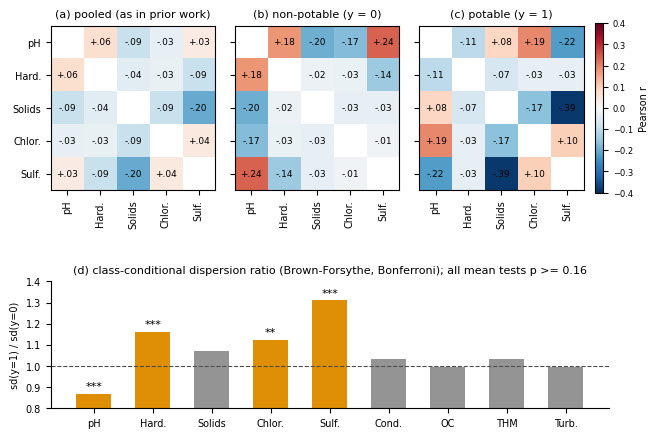

In [7]:
import matplotlib.pyplot as plt

SHORT_NAME = {"ph": "pH", "Hardness": "Hard.", "Solids": "Solids", "Chloramines": "Chlor.", "Sulfate": "Sulf.",
              "Conductivity": "Cond.", "Organic_carbon": "OC", "Trihalomethanes": "THM", "Turbidity": "Turb."}
idx = [FEATURES.index(f) for f in SODS_KEPT]
names = [SHORT_NAME[FEATURES[i]] for i in idx]

fig = plt.figure(figsize=(7.2, 5.0))
gs = fig.add_gridspec(2, 3, height_ratios=[1.0, 0.75], hspace=0.6, wspace=0.12)
titles = ["(a) pooled (as in prior work)", "(b) non-potable (y = 0)", "(c) potable (y = 1)"]
for k, cls in enumerate([None, 0, 1]):
    ax = fig.add_subplot(gs[0, k])
    R = np.full((len(idx), len(idx)), np.nan)
    for a, i in enumerate(idx):
        for b, j in enumerate(idx):
            if a != b:
                R[a, b] = corr(i, j, cls)
    im = ax.imshow(R, cmap="RdBu_r", vmin=-0.4, vmax=0.4)
    for a in range(len(idx)):
        for b in range(len(idx)):
            if a != b:
                ax.text(b, a, f"{R[a, b]:+.2f}".replace("0.", "."), ha="center", va="center", fontsize=6.5)
    ax.set_xticks(range(len(idx)))
    ax.set_xticklabels(names, rotation=90, fontsize=7)
    ax.set_yticks(range(len(idx)))
    ax.set_yticklabels(names if k == 0 else [], fontsize=7)
    ax.set_title(titles[k], fontsize=8)
cbar = fig.colorbar(im, ax=fig.axes[:3], fraction=0.025, pad=0.02)
cbar.set_label("Pearson r", fontsize=7)
cbar.ax.tick_params(labelsize=6)

ax = fig.add_subplot(gs[1, :])
ax.bar(range(d), bf.sd_ratio, width=0.6, color=["#de8f05" if s else "#949494" for s in bf.bonferroni])
ax.axhline(1.0, ls="--", lw=0.8, color="0.3")
for j, (r, p) in enumerate(zip(bf.sd_ratio, bf.p)):
    stars = "***" if p < 1e-4 else "**" if p < 1e-3 else "*" if p < 0.05 / d else ""
    ax.text(j, r + 0.01, stars, ha="center", va="bottom", fontsize=8)
ax.set_xticks(range(d))
ax.set_xticklabels([SHORT_NAME[f] for f in FEATURES], fontsize=7)
ax.set_ylim(0.8, 1.4)
ax.set_ylabel("sd(y=1) / sd(y=0)", fontsize=7)
ax.tick_params(axis="y", labelsize=7)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.set_title(f"(d) class-conditional dispersion ratio (Brown-Forsythe, Bonferroni); "
             f"all mean tests p >= {min(welch_p):.2f}", fontsize=8)
fig.savefig(f"{OUT}/second_order_structure.png", dpi=300, bbox_inches="tight")
fig.savefig(f"{OUT}/second_order_structure.pdf", bbox_inches="tight")
plt.show()

## Resamplers and class weights
Resampling happens inside `fit` only, so prediction never sees synthetic rows. The scikit-learn screens and the protocol reconstructions use the built-in ROS, RUS and SMOTE below; the other resamplers and the boosting-library runs use imbalanced-learn. `CW` uses each library's own weighting (`scale_pos_weight` per fold for XGBoost, `auto_class_weights` for CatBoost, equal priors for QDA); learners without one show n/a.

In [8]:
from sklearn.utils.metaestimators import available_if

if HAS["imblearn"]:
    try:   # test a fit, not just the import
        from imblearn.over_sampling import SMOTE as _SMOTE
        _rs = np.random.RandomState(0)
        _SMOTE(random_state=0).fit_resample(_rs.rand(40, 3), np.r_[np.zeros(28), np.ones(12)].astype(int))
    except Exception as e:
        HAS["imblearn"] = False
        print(f"imbalanced-learn failed a test fit ({type(e).__name__}: {e})")
if HAS["imblearn"]:
    print("imbalanced-learn", VERSIONS.get("imblearn"), "is used for all resampling")
else:
    print("WARNING: imbalanced-learn is not usable, so built-in ROS / RUS / SMOTE stand-ins are used. M0b, M5, "
          "M5b, M6 and the resampling strategies will change. Fix: turn Internet on, run "
          "!pip install -U imbalanced-learn, restart the session and run all cells again.")

_FALLBACK_WARNED = set()

def make_sampler(name, random_state=0, impl="auto"):
    """impl="builtin": the built-in ROS, RUS and SMOTE below; otherwise imbalanced-learn when it is available."""
    if name in (None, "none", "CW", "TM-F1"):
        return None
    if HAS["imblearn"] and not (impl == "builtin" and name in ("ROS", "RUS", "SMOTE")):
        from imblearn.over_sampling import SMOTE, BorderlineSMOTE, ADASYN, RandomOverSampler
        from imblearn.under_sampling import RandomUnderSampler
        from imblearn.combine import SMOTETomek, SMOTEENN
        table = {"ROS": RandomOverSampler, "RUS": RandomUnderSampler, "SMOTE": SMOTE,
                 "B-SMOTE": BorderlineSMOTE, "ADASYN": ADASYN, "SMOTE-Tomek": SMOTETomek,
                 "SMOTE-ENN": SMOTEENN}
        return table[name](random_state=random_state)
    if name not in ("ROS", "RUS", "SMOTE") and name not in _FALLBACK_WARNED:
        print(f"WARNING: without imbalanced-learn, '{name}' runs as plain SMOTE")
        _FALLBACK_WARNED.add(name)
    class _Simple:                                   # ROS / RUS / SMOTE stand-ins
        def __init__(self, kind, rs):
            self.kind, self.rs = kind, rs
        def fit_resample(self, X, y):
            rng = np.random.RandomState(self.rs)
            X, y = np.asarray(X, float), np.asarray(y)
            maj, mino = (0, 1) if (y == 0).sum() > (y == 1).sum() else (1, 0)
            Xm, Xn = X[y == maj], X[y == mino]
            if self.kind == "RUS":
                sel = rng.choice(len(Xm), len(Xn), replace=False)
                return np.vstack([Xm[sel], Xn]), np.r_[np.full(len(Xn), maj), np.full(len(Xn), mino)]
            k = len(Xm) - len(Xn)
            if self.kind == "ROS":
                new = Xn[rng.randint(0, len(Xn), k)]
            else:                                    # SMOTE
                from sklearn.neighbors import NearestNeighbors
                nn = NearestNeighbors(n_neighbors=min(6, len(Xn))).fit(Xn)
                _, ind = nn.kneighbors(Xn)
                b = rng.randint(0, len(Xn), k)
                nb = ind[b, rng.randint(1, ind.shape[1], k)]
                lam = rng.rand(k, 1)
                new = Xn[b] + lam * (Xn[nb] - Xn[b])
            return np.vstack([X, new]), np.r_[y, np.full(k, mino)]
    return _Simple(name if name in ("ROS", "RUS") else "SMOTE", random_state)

def _inner_has(attr):
    def check(self):
        return hasattr(getattr(self, "estimator_", self.estimator), attr)
    return check

class ResampledClassifier(ClassifierMixin, BaseEstimator):
    def __init__(self, estimator=None, sampler=None, random_state=0, impl="auto"):
        self.estimator, self.sampler, self.random_state, self.impl = estimator, sampler, random_state, impl

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y)
        s = make_sampler(self.sampler, self.random_state, self.impl)
        if s is not None:
            X, y = s.fit_resample(X, y)
        self.estimator_ = clone(self.estimator).fit(X, y)
        self.classes_ = self.estimator_.classes_
        return self

    def predict(self, X):
        return self.estimator_.predict(np.asarray(X, float))

    @available_if(_inner_has("predict_proba"))
    def predict_proba(self, X):
        return self.estimator_.predict_proba(np.asarray(X, float))

    @available_if(_inner_has("decision_function"))
    def decision_function(self, X):
        return self.estimator_.decision_function(np.asarray(X, float))

class ThresholdMoved(ClassifierMixin, BaseEstimator):
    """F1-optimal threshold chosen on inner out-of-fold predictions of the training fold."""
    def __init__(self, estimator=None, inner=3, random_state=0):
        self.estimator, self.inner, self.random_state = estimator, inner, random_state

    def fit(self, X, y):
        from sklearn.model_selection import cross_val_predict
        X, y = np.asarray(X, float), np.asarray(y)
        cv = StratifiedKFold(self.inner, shuffle=True, random_state=self.random_state)
        oof = cross_val_predict(clone(self.estimator), X, y, cv=cv, method="predict_proba")[:, 1]
        grid = np.quantile(oof, np.linspace(0.05, 0.95, 37))
        self.threshold_ = float(max(grid, key=lambda t: f1_score(y, (oof >= t).astype(int), zero_division=0)))
        self.estimator_ = clone(self.estimator).fit(X, y)
        self.classes_ = self.estimator_.classes_
        return self

    def predict_proba(self, X):
        return self.estimator_.predict_proba(np.asarray(X, float))

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= self.threshold_).astype(int)

class FoldScalePosWeight(ClassifierMixin, BaseEstimator):
    """XGBoost class weighting: scale_pos_weight = n_neg / n_pos, counted on each training fold."""
    def __init__(self, estimator=None):
        self.estimator = estimator

    def fit(self, X, y):
        y = np.asarray(y)
        self.scale_pos_weight_ = float((y == 0).sum()) / max(float((y == 1).sum()), 1.0)
        self.estimator_ = clone(self.estimator).set_params(scale_pos_weight=self.scale_pos_weight_).fit(X, y)
        self.classes_ = self.estimator_.classes_
        return self

    def predict_proba(self, X):
        return self.estimator_.predict_proba(X)

    def predict(self, X):
        return self.estimator_.predict(X)

def class_weighted(clf):
    """The learner with balanced class weights, or None if it has no weighting option."""
    if type(clf).__name__ == "CatBoostClassifier":
        return clf.set_params(auto_class_weights="Balanced")
    if type(clf).__name__ == "QuadraticDiscriminantAnalysis":   # equal class priors
        return clf.set_params(priors=[0.5, 0.5])
    if type(clf).__name__ == "MarginalQDA":
        return clf.set_params(equal_priors=True)
    params = clf.get_params()
    if "class_weight" in params:                     # scikit-learn, LightGBM
        return clf.set_params(class_weight="balanced")
    if "scale_pos_weight" in params:                 # XGBoost
        return FoldScalePosWeight(clf)
    return None

imbalanced-learn 0.14.2 is used for all resampling


## Model zoo
Tuned settings for the scikit-learn learners, and XGBoost, LightGBM and CatBoost with 400 / 400 / 500 trees, depth 5 to 6 and learning rate 0.05. Each boosting library gets a short compatibility test first and is skipped with a message if it fails.

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier,
                              StackingClassifier, VotingClassifier)
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from sklearn.base import is_classifier

def gbdt_lib(name, seed=0, **kw):
    """Factory for XGBoost, LightGBM and CatBoost."""
    if name == "XGBoost":
        from xgboost import XGBClassifier
        p = dict(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                 reg_lambda=1.0, eval_metric="logloss", tree_method="hist", n_jobs=N_JOBS,
                 random_state=seed)
        p.update(kw)
        return XGBClassifier(**p)
    if name == "LightGBM":
        from lightgbm import LGBMClassifier
        # LightGBM ignores subsample unless subsample_freq > 0
        p = dict(n_estimators=400, num_leaves=31, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                 min_child_samples=20, n_jobs=N_JOBS, random_state=seed, verbose=-1)
        p.update(kw)
        return LGBMClassifier(**p)
    if name == "CatBoost":
        from catboost import CatBoostClassifier
        p = dict(iterations=500, depth=6, learning_rate=0.05, l2_leaf_reg=3.0, random_seed=seed,
                 verbose=0, allow_writing_files=False, thread_count=N_JOBS)
        p.update(kw)
        return CatBoostClassifier(**p)
    raise ValueError(name)

def ensure_classifier_tags(cls):
    """scikit-learn >= 1.6 reads estimator tags; give them to a library class that lacks them."""
    try:
        if is_classifier(cls()):
            return False
    except Exception:
        pass
    class _Reference(ClassifierMixin, BaseEstimator):
        pass
    def __sklearn_tags__(self):
        tags = _Reference().__sklearn_tags__()
        tags.input_tags.allow_nan = True
        return tags
    cls._estimator_type = "classifier"
    if hasattr(BaseEstimator, "__sklearn_tags__"):
        cls.__sklearn_tags__ = __sklearn_tags__
    return True

LIB_CLASSES = {"XGBoost": ("xgboost", "XGBClassifier"), "LightGBM": ("lightgbm", "LGBMClassifier"),
               "CatBoost": ("catboost", "CatBoostClassifier")}
for lib, (mod, cls_name) in LIB_CLASSES.items():
    if HAS[mod]:
        if ensure_classifier_tags(getattr(__import__(mod), cls_name)):
            print(f"note: added scikit-learn tags to {cls_name}; this {lib} build does not define them")

BASE_LEARNERS = {
    "LR": lambda s=0: LogisticRegression(C=0.38, max_iter=4000),
    "SVM": lambda s=0: SVC(C=4.0, gamma=0.1, probability=True, random_state=s),
    "ET": lambda s=0: ExtraTreesClassifier(n_estimators=300, max_depth=16, min_samples_leaf=4,
                                           max_features=0.35, n_jobs=N_JOBS, random_state=s),
    "RF": lambda s=0: RandomForestClassifier(n_estimators=300, min_samples_leaf=2, max_features=0.5,
                                             n_jobs=N_JOBS, random_state=s),
    "GBDT-sk": lambda s=0: HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, random_state=s),
    "MQDA": lambda s=0: MarginalQDA(reg=0.05),
    # starting points for the learners tuned in Part D
    "KNN": lambda s=0: KNeighborsClassifier(n_neighbors=25),
    "QDA": lambda s=0: QuadraticDiscriminantAnalysis(reg_param=1e-3),
    "MLP": lambda s=0: MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=500, random_state=s),
}
for lib in LIB_CLASSES:
    if HAS[LIB_CLASSES[lib][0]]:
        BASE_LEARNERS[lib] = (lambda name: (lambda s=0: gbdt_lib(name, s)))(lib)

REPRS = ["raw-std", "SOMF", "SODS", "SODS+SOMF"]
RESAMPLERS = {"ROS", "RUS", "SMOTE", "B-SMOTE", "ADASYN", "SMOTE-Tomek", "SMOTE-ENN"}

class NotApplicable(Exception):
    """The learner has no way to apply the requested strategy (reported as n/a)."""

def build_pipeline(learner, repr_name="SODS+SOMF", strategy="none", imputer="median", seed=0):
    """Fold-confined pipeline: every step below is refitted inside each training fold."""
    steps = []
    if repr_name in ("SODS", "SODS+SOMF"):
        steps.append(("sods", SODSelector()))
    has_somf = repr_name in ("SOMF", "SODS+SOMF")
    if has_somf:
        steps.append(("somf", SecondOrderMoments()))
    clf = BASE_LEARNERS[learner](seed)
    # these four handle NaN natively
    needs_imputation = learner not in ("GBDT-sk", "MQDA", "XGBoost", "LightGBM")
    if has_somf:
        needs_imputation = False                       # SOMF fills its own NaN
    elif strategy in RESAMPLERS:
        needs_imputation = True                        # resamplers need complete rows
    if needs_imputation:
        steps.append(("imp", SimpleImputer(strategy=imputer)))
    if learner in ("LR", "SVM", "KNN", "QDA", "MLP"):
        steps.append(("sc", StandardScaler()))
    if strategy == "CW":
        clf = class_weighted(clf)
        if clf is None:
            raise NotApplicable(f"{learner} has no class-weight option")
    elif strategy == "TM-F1":
        clf = ThresholdMoved(clf, random_state=seed)
    elif strategy in RESAMPLERS:
        clf = ResampledClassifier(clf, strategy, seed)
    elif strategy != "none":
        raise ValueError(f"unknown strategy {strategy}")
    steps.append(("clf", clf))
    return Pipeline(steps)

def cv_evaluate(pipe, X, y, folds, name=""):
    rows = []
    for k, (tr, te) in enumerate(folds):
        est = clone(pipe).fit(X[tr], y[tr])
        s = scores_of(est, X[te])
        m = all_metrics(y[te], est.predict(X[te]), s)
        m.update(fold=k, model=name)
        rows.append(m)
    return pd.DataFrame(rows)

def library_works(lib):
    """Short test of everything the long runs ask of a boosting library."""
    try:
        Xs, ys = Xtr[:400], ytr[:400]
        build_pipeline(lib, "SODS+SOMF", "none").fit(Xs, ys).predict_proba(Xs[:5])
        build_pipeline(lib, "raw-std", "CW").fit(Xs, ys).predict(Xs[:5])
        StackingClassifier([("m", build_pipeline(lib, "raw-std", "none")), ("lr", build_pipeline("LR", "raw-std"))],
                           final_estimator=LogisticRegression(), cv=3).fit(Xs, ys).predict_proba(Xs[:5])
        RandomizedSearchCV(build_pipeline(lib, "raw-std", "none"), {"clf__learning_rate": [0.05, 0.1]}, n_iter=2,
                           scoring="roc_auc", cv=StratifiedKFold(3), refit=False, random_state=0).fit(Xs, ys)
        return True
    except Exception as e:
        print(f"WARNING: {lib} is skipped because it failed the compatibility test ({type(e).__name__}: {e}). "
              f"Fix: turn Internet on and run !pip install -U {LIB_CLASSES[lib][0]}, then restart.")
        return False

NEW_LIBS = [lib for lib in LIB_CLASSES if lib in BASE_LEARNERS and library_works(lib)]
for lib in LIB_CLASSES:
    if lib in BASE_LEARNERS and lib not in NEW_LIBS:
        del BASE_LEARNERS[lib]
print("learners:", list(BASE_LEARNERS))
print("boosting libraries used here:", NEW_LIBS)
if len(NEW_LIBS) < 3:
    print("WARNING: the boosting-library results need XGBoost, LightGBM and CatBoost.")

t0 = time.time()
_demo = cv_evaluate(build_pipeline("ET", "SODS+SOMF", "none"), Xtr, ytr, cv_folds(Xtr, ytr, reps=1), "ET check")
print(f"sanity check, ET on SODS+SOMF: AUC {_demo.auc.mean():.3f}, acc {_demo.acc.mean():.3f} "
      f"({time.time() - t0:.1f}s for 5 folds)")

learners: ['LR', 'SVM', 'ET', 'RF', 'GBDT-sk', 'MQDA', 'KNN', 'QDA', 'MLP', 'XGBoost', 'LightGBM', 'CatBoost']
boosting libraries used here: ['XGBoost', 'LightGBM', 'CatBoost']
sanity check, ET on SODS+SOMF: AUC 0.725, acc 0.689 (5.5s for 5 folds)


# A. Leakage attribution
Eleven pipelines (M0 to M7) with RF, XGBoost, LightGBM and CatBoost over 10 stratified 80/20 splits. Boost. is the mean of the three boosting libraries. The last two columns split RF accuracy into leak-carrying and other rows: rows with a missing value for M0 to M4, generated rows for M5 and M6.

In [10]:
from sklearn.svm import SVR

def svr_impute(df_in, use_label=False):
    """Sequential SVR imputation as described by Yurtsever & Emec; use_label leaks the target."""
    d = df_in.copy()
    preds = {"Trihalomethanes": ["Chloramines", "Conductivity"],
             "ph": ["Hardness", "Sulfate", "Conductivity", "Organic_carbon", "Trihalomethanes"],
             "Sulfate": ["ph", "Organic_carbon", "Chloramines"]}
    for col in ["Trihalomethanes", "ph", "Sulfate"]:
        P = d[preds[col] + ([TARGET] if use_label else [])].astype(float).copy()
        P = P.fillna(P.mean())
        Pz = (P - P.mean()) / P.std()
        obs = d[col].notna()
        mu, sd = d.loc[obs, col].mean(), d.loc[obs, col].std()
        m = SVR(kernel="poly", degree=2, gamma="auto", C=1.2).fit(Pz[obs], (d.loc[obs, col] - mu) / sd)
        d.loc[~obs, col] = m.predict(Pz[~obs]) * sd + mu
    return d

def run_leakage(models=None, n_seeds=N_SEEDS_LEAK):
    models = models or (["RF"] + NEW_LIBS)
    dfa, X, y = load()
    n = len(y)
    Xmean = SimpleImputer(strategy="mean").fit_transform(X)
    Xmean_z = StandardScaler().fit_transform(Xmean)
    Xsvr = StandardScaler().fit_transform(svr_impute(dfa)[FEATURES].to_numpy(float))
    Xsvr_lab = StandardScaler().fit_transform(svr_impute(dfa, True)[FEATURES].to_numpy(float))
    Xclass = dfa[FEATURES].fillna(dfa.groupby(TARGET)[FEATURES].transform("mean")).to_numpy(float)
    miss = np.isnan(X).any(1)
    rows = []

    def rec(mech, mod, seed, yt, yh, s, grp=None, names=("leak_rows", "other_rows")):
        m = all_metrics(yt, yh, s)
        m.update(mechanism=mech, model=mod, seed=seed, n_test=len(yt))
        if grp is not None:
            ok = yt == yh
            m["acc_" + names[0]] = float(ok[grp].mean()) if grp.any() else np.nan
            m["acc_" + names[1]] = float(ok[~grp].mean()) if (~grp).any() else np.nan
        rows.append(m)

    for seed in range(n_seeds):
        tr, te = train_test_split(np.arange(n), test_size=0.2, stratify=y, random_state=seed)
        yt, g = y[te], miss[te]
        Xs, ys = make_sampler("SMOTE", seed).fit_resample(Xmean_z, y)
        Xo, yo = make_sampler("ROS", seed).fit_resample(Xmean_z, y)
        for mod in models:
            mk = lambda: BASE_LEARNERS[mod](seed)
            p = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("c", mk())])
            p.fit(X[tr], y[tr])
            rec("M0 leak-free (in-fold)", mod, seed, yt, p.predict(X[te]), scores_of(p, X[te]), g)
            p = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()),
                          ("c", ResampledClassifier(mk(), "SMOTE", seed))]).fit(X[tr], y[tr])
            rec("M0b leak-free + in-fold SMOTE", mod, seed, yt, p.predict(X[te]), scores_of(p, X[te]))
            for mech, XX in [("M1 global mean imputation", Xmean), ("M2 global imputation + scaling", Xmean_z),
                             ("M3 global SVR imputation", Xsvr), ("M3b label-aware SVR imputation", Xsvr_lab),
                             ("M4 class-mean imputation", Xclass)]:
                c = mk().fit(XX[tr], y[tr])
                rec(mech, mod, seed, yt, c.predict(XX[te]), scores_of(c, XX[te]), g)
            rows_tr = np.concatenate([tr, np.arange(n, len(ys))])
            c = mk().fit(Xs[rows_tr], ys[rows_tr])
            rec("M5b pre-split SMOTE, authentic test", mod, seed, yt, c.predict(Xmean_z[te]),
                scores_of(c, Xmean_z[te]))
            for mech, (XR, yR) in [("M5 pre-split SMOTE", (Xs, ys)), ("M6 pre-split ROS", (Xo, yo))]:
                a, b = train_test_split(np.arange(len(yR)), test_size=0.2, stratify=yR, random_state=seed)
                c = mk().fit(XR[a], yR[a])
                rec(mech, mod, seed, yR[b], c.predict(XR[b]), scores_of(c, XR[b]), b >= n,
                    ("generated_rows", "original_rows"))
            c = mk().fit(Xmean_z, y)
            rec("M7 scored rows in training", mod, seed, yt, c.predict(Xmean_z[te]), scores_of(c, Xmean_z[te]))
        print(f"  leakage split {seed} done ({time.time() - t0:.0f}s elapsed)")
    return pd.DataFrame(rows)

MECHANISMS = ["M0 leak-free (in-fold)", "M0b leak-free + in-fold SMOTE", "M1 global mean imputation",
              "M2 global imputation + scaling", "M3 global SVR imputation", "M3b label-aware SVR imputation",
              "M4 class-mean imputation", "M5 pre-split SMOTE", "M5b pre-split SMOTE, authentic test",
              "M6 pre-split ROS", "M7 scored rows in training"]

def leakage_summary(leak):
    """RF and mean-of-boosters accuracy and ROC-AUC, plus RF accuracy on leak-carrying vs. other rows."""
    g = leak.groupby(["mechanism", "model"]).mean(numeric_only=True)
    boost = [m for m in ["XGBoost", "LightGBM", "CatBoost"] if m in set(leak.model)]
    rows = []
    for mech in MECHANISMS:
        r = g.loc[(mech, "RF")]
        cols = (("acc_generated_rows", "acc_original_rows") if mech.startswith(("M5 ", "M6 "))
                else ("acc_leak_rows", "acc_other_rows"))
        rows.append({"mechanism": mech, "RF acc": r["acc"],
                     "Boost acc": np.mean([g.loc[(mech, b), "acc"] for b in boost]) if boost else np.nan,
                     "RF AUC": r["auc"],
                     "Boost AUC": np.mean([g.loc[(mech, b), "auc"] for b in boost]) if boost else np.nan,
                     "RF leak": r.get(cols[0], np.nan), "RF other": r.get(cols[1], np.nan)})
    return pd.DataFrame(rows).set_index("mechanism")

t0 = time.time()
leak = run_leakage()
leak.to_csv(f"{OUT}/kaggle_leakage_runs.csv", index=False)
per_model = leak.groupby(["mechanism", "model"])[["acc", "auc"]].mean().unstack("model")
print("\nmean over splits, per model")
print(per_model.loc[MECHANISMS].round(3).to_string())
print("\nsummary (Boost. = mean of the boosting libraries)")
print(leakage_summary(leak).round(3).to_string())

  leakage split 0 done (60s elapsed)
  leakage split 1 done (118s elapsed)
  leakage split 2 done (175s elapsed)
  leakage split 3 done (231s elapsed)
  leakage split 4 done (288s elapsed)
  leakage split 5 done (352s elapsed)
  leakage split 6 done (418s elapsed)
  leakage split 7 done (477s elapsed)
  leakage split 8 done (538s elapsed)
  leakage split 9 done (599s elapsed)

mean over splits, per model
                                         acc                              auc                        
model                               CatBoost LightGBM     RF XGBoost CatBoost LightGBM     RF XGBoost
mechanism                                                                                            
M0 leak-free (in-fold)                 0.671    0.652  0.675   0.659    0.690    0.663  0.689   0.669
M0b leak-free + in-fold SMOTE          0.641    0.624  0.647   0.633    0.686    0.657  0.685   0.670
M1 global mean imputation              0.669    0.649  0.675   0.658    0.690    0

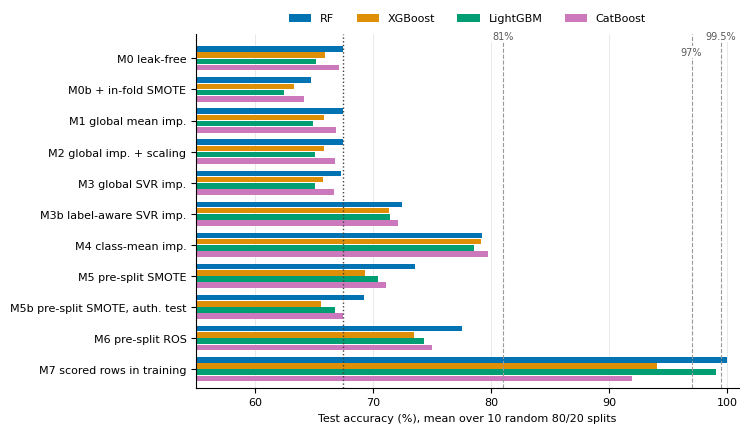

In [11]:
LEAK_LABELS = ["M0 leak-free", "M0b + in-fold SMOTE", "M1 global mean imp.", "M2 global imp. + scaling",
               "M3 global SVR imp.", "M3b label-aware SVR imp.", "M4 class-mean imp.", "M5 pre-split SMOTE",
               "M5b pre-split SMOTE, auth. test", "M6 pre-split ROS", "M7 scored rows in training"]
MODEL_COLORS = {"RF": "#0173b2", "XGBoost": "#de8f05", "LightGBM": "#029e73", "CatBoost": "#cc78bc"}

acc_pct = leak.groupby(["mechanism", "model"]).acc.mean().unstack() * 100
fig_models = [m for m in MODEL_COLORS if m in acc_pct.columns]
h = 0.8 / len(fig_models)
ypos = np.arange(len(MECHANISMS))[::-1]
fig, ax = plt.subplots(figsize=(7.0, 4.6))
for k, m in enumerate(fig_models):
    ax.barh(ypos + 0.4 - (k + 0.5) * h, acc_pct.loc[MECHANISMS, m].values, height=h * 0.9,
            color=MODEL_COLORS[m], label=m)
ax.axvline(acc_pct.loc[MECHANISMS[0], "RF"], ls=":", lw=1.0, color="0.25")       # leak-free level
for v, lab, dy in [(81, "81%", 0.55), (97, "97%", 0.05), (99.5, "99.5%", 0.55)]:  # J. Patel, Al Mamun, S. Patel et al.
    ax.axvline(v, ls="--", lw=0.8, color="0.6")
    ax.text(v, ypos[0] + dy, lab, ha="center", va="bottom", fontsize=7, color="0.35",
            bbox=dict(facecolor="white", edgecolor="none", pad=0.5))
ax.set_yticks(ypos)
ax.set_yticklabels(LEAK_LABELS, fontsize=8)
ax.set_xlim(55, 101)
ax.set_ylim(-0.6, len(MECHANISMS) - 0.2)
ax.set_xlabel(f"Test accuracy (%), mean over {N_SEEDS_LEAK} random 80/20 splits", fontsize=8)
ax.tick_params(axis="x", labelsize=8)
ax.grid(axis="x", lw=0.4, alpha=0.5)
ax.set_axisbelow(True)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.legend(ncol=len(fig_models), loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False, fontsize=8)
fig.savefig(f"{OUT}/leakage_accuracy.png", dpi=300, bbox_inches="tight")
fig.savefig(f"{OUT}/leakage_accuracy.pdf", bbox_inches="tight")
plt.show()

# B. Reconstruction of published protocols
Four published pipelines on this dataset, each run as its authors describe it, over 10 random splits. "XGB-like" is HistGradientBoosting with XGBoost's default depth (6) and learning rate (0.3); with XGBoost installed, the same protocols also run with the real library.

In [12]:
dfa, X3, y3 = load()
X3_mean = SimpleImputer(strategy="mean").fit_transform(X3)
X3_z = StandardScaler().fit_transform(X3_mean)                  # global mean imputation + z-score
X3_mm = MinMaxScaler().fit_transform(X3_mean)                   # global mean imputation + min-max scaling
X3_svr = StandardScaler().fit_transform(svr_impute(dfa)[FEATURES].to_numpy(float))
X3_svr_lab = svr_impute(dfa, True)[FEATURES].to_numpy(float)
X3_class = dfa[FEATURES].fillna(dfa.groupby(TARGET)[FEATURES].transform("mean")).to_numpy(float)
complete = ~np.isnan(X3).any(1)

RF_DEFAULT = lambda s: RandomForestClassifier(random_state=s, n_jobs=N_JOBS)
XGB_LIKE = lambda s: HistGradientBoostingClassifier(max_depth=6, learning_rate=0.3, max_leaf_nodes=None, random_state=s)
STUMPS = lambda s: HistGradientBoostingClassifier(max_iter=1000, max_depth=1, random_state=s)

protocol_rows = []
def protocol(study, label, reported, XX, yy, mk, test=0.2, score_training_rows=False, resample=None):
    accs = []
    for s in range(10):
        XR, yR = make_sampler(resample, s, impl="builtin").fit_resample(XX, yy) if resample else (XX, yy)
        tr, te = train_test_split(np.arange(len(yR)), test_size=test, stratify=yR, random_state=s)
        fit_rows = np.arange(len(yR)) if score_training_rows else tr
        c = mk(s).fit(XR[fit_rows], yR[fit_rows])
        accs.append(100 * accuracy_score(yR[te], c.predict(XR[te])))
    protocol_rows.append(dict(study=study, protocol=label, reported=reported, mean=np.mean(accs),
                              sd=np.std(accs, ddof=1)))
    print(f"  {study:18s} {label:40s} reported {reported:6.2f} | this run {np.mean(accs):5.1f} ± "
          f"{np.std(accs, ddof=1):.1f}")

protocol("Obulezi et al.", "Global mean imp. + z, RBF-SVM", 67.13, X3_z, y3, lambda s: SVC())
protocol("J. Patel et al.", "Pre-split SMOTE, pooled test, RF", 81.00, X3_z, y3, RF_DEFAULT, test=0.3,
         resample="SMOTE")
protocol("S. Patel et al.", "Global imp. + scaling, XGB-like", 99.51, X3_mm, y3, XGB_LIKE, test=0.3)
protocol("S. Patel et al.", "  scored rows in training, XGB-like", 99.51, X3_mm, y3, XGB_LIKE, test=0.3,
         score_training_rows=True)
protocol("S. Patel et al.", "  scored rows in training, RF", 99.51, X3_mm, y3, RF_DEFAULT, test=0.3,
         score_training_rows=True)
protocol("Yurtsever & Emec", "SVR imp., 1000 stumps (SXH)", 99.54, X3_svr, y3, STUMPS)
protocol("Yurtsever & Emec", "  DROP arm: complete cases, RF", 66.75, X3[complete], y3[complete], RF_DEFAULT)
protocol("Yurtsever & Emec", "  MEAN arm: global mean, RF", 81.41, X3_mean, y3, RF_DEFAULT)
protocol("Yurtsever & Emec", "  class-mean imp., RF", 81.41, X3_class, y3, RF_DEFAULT)
protocol("Yurtsever & Emec", "  REGR. arm: label-aware SVR, RF", 90.24, X3_svr_lab, y3, RF_DEFAULT)
if "XGBoost" in NEW_LIBS:
    from xgboost import XGBClassifier
    xgb = lambda s, **kw: XGBClassifier(eval_metric="logloss", n_jobs=N_JOBS, random_state=s, **kw)
    protocol("S. Patel et al.", "Global imp. + scaling, XGBoost", 99.51, X3_mm, y3, xgb, test=0.3)
    protocol("S. Patel et al.", "  scored rows in training, XGBoost", 99.51, X3_mm, y3, xgb, test=0.3,
             score_training_rows=True)
    protocol("Yurtsever & Emec", "SVR imp., 1000 stumps, XGBoost", 99.54, X3_svr, y3,
             lambda s: xgb(s, n_estimators=1000, max_depth=1))
protocols = pd.DataFrame(protocol_rows)
protocols.to_csv(f"{OUT}/protocol_reconstructions.csv", index=False)

  Obulezi et al.     Global mean imp. + z, RBF-SVM            reported  67.13 | this run  67.7 ± 1.5
  J. Patel et al.    Pre-split SMOTE, pooled test, RF         reported  81.00 | this run  72.4 ± 1.2
  S. Patel et al.    Global imp. + scaling, XGB-like          reported  99.51 | this run  63.0 ± 1.4
  S. Patel et al.      scored rows in training, XGB-like      reported  99.51 | this run  99.2 ± 0.3
  S. Patel et al.      scored rows in training, RF            reported  99.51 | this run 100.0 ± 0.0
  Yurtsever & Emec   SVR imp., 1000 stumps (SXH)              reported  99.54 | this run  61.3 ± 1.8
  Yurtsever & Emec     DROP arm: complete cases, RF           reported  66.75 | this run  68.8 ± 1.6
  Yurtsever & Emec     MEAN arm: global mean, RF              reported  81.41 | this run  67.0 ± 1.5
  Yurtsever & Emec     class-mean imp., RF                    reported  81.41 | this run  79.1 ± 1.2
  Yurtsever & Emec     REGR. arm: label-aware SVR, RF         reported  90.24 | this run  7

# C. Component screening
5-fold CV on the training partition: nine representations and five imputers for eight learners, then ten imbalance strategies on each learner's best representation. The screening learners use library defaults (kNN with k = 25, QDA with a 0.001 ridge).

In [13]:
from sklearn.preprocessing import PowerTransformer, QuantileTransformer

SCREEN_LEARNERS = {
    "LR": lambda s=0: LogisticRegression(max_iter=4000),
    "KNN": lambda s=0: KNeighborsClassifier(n_neighbors=25),
    "SVM": lambda s=0: SVC(probability=True, random_state=s),
    "QDA": lambda s=0: QuadraticDiscriminantAnalysis(reg_param=1e-3),
    "MLP": lambda s=0: MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=500, random_state=s),
    "ET": lambda s=0: ExtraTreesClassifier(n_estimators=300, n_jobs=N_JOBS, random_state=s),
    "RF": lambda s=0: RandomForestClassifier(n_estimators=300, n_jobs=N_JOBS, random_state=s),
    "HGB": lambda s=0: HistGradientBoostingClassifier(random_state=s),
}
SCREEN_ORDER = list(SCREEN_LEARNERS)
ALL_REPRS = ["raw-std", "raw-minmax", "yeo-johnson", "quantile-normal", "raw+MI", "WHO-domain", "SOMF", "SODS",
              "SODS+SOMF"]
TREES = ("ET", "RF", "HGB")

class WHOFeatures(TransformerMixin, BaseEstimator):
    """Raw features plus one exceedance flag per WHO guideline (WHO_LIMITS above)."""
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = np.asarray(X, float)
        flags = [(X[:, j] > hi) | ((X[:, j] < lo) if lo is not None else False)
                 for j, (lo, hi) in enumerate(WHO_LIMITS[f] for f in FEATURES)]
        return np.hstack([X, np.column_stack(flags).astype(float)])

def with_strategy(clf, learner, strategy, seed=0):
    if strategy == "CW":
        clf = class_weighted(clf)
        if clf is None:
            raise NotApplicable(f"{learner} has no class-weight option")
        return clf
    if strategy == "TM-F1":
        return ThresholdMoved(clf, random_state=seed)
    if strategy in RESAMPLERS:
        return ResampledClassifier(clf, strategy, seed, impl="builtin")
    if strategy != "none":
        raise ValueError(strategy)
    return clf

def screen_pipeline(learner, rep="raw-std", strategy="none", seed=0):
    """Representation, then its scaler (trees skip it), then the learner."""
    steps = [("sods", SODSelector())] if rep.startswith("SODS") else []
    if "SOMF" in rep:
        steps.append(("somf", SecondOrderMoments()))
    else:
        steps.append(("imp", SimpleImputer(strategy="median", add_indicator=(rep == "raw+MI"))))
    if rep == "WHO-domain":
        steps.append(("who", WHOFeatures()))
    if learner not in TREES:
        steps.append(("sc", {"raw-minmax": MinMaxScaler(), "yeo-johnson": PowerTransformer(),
                             "quantile-normal": QuantileTransformer(output_distribution="normal", random_state=0)
                             }.get(rep, StandardScaler())))
    steps.append(("clf", with_strategy(SCREEN_LEARNERS[learner](seed), learner, strategy, seed)))
    return Pipeline(steps)

folds1 = cv_folds(Xtr, ytr, reps=1)
rows, t = [], time.time()
for lrn in SCREEN_ORDER:
    for rep in ALL_REPRS:
        if lrn == "QDA" and "SOMF" in rep:                  # QDA is not fitted on the rank-deficient SOMF
            continue
        if lrn in TREES and rep in ("raw-minmax", "yeo-johnson", "quantile-normal"):
            rows.append(dict(rows[-1], repr=rep))           # monotone transforms leave trees unchanged
            continue
        r = cv_evaluate(screen_pipeline(lrn, rep), Xtr, ytr, folds1)
        rows.append(dict(learner=lrn, repr=rep, auc=r.auc.mean(), mcc=r.mcc.mean(), acc=r.acc.mean()))
    print(f"  {lrn} done ({time.time() - t:.0f}s)")
sk_repr_screen = pd.DataFrame(rows)
sk_repr_screen.to_csv(f"{OUT}/screen_representations.csv", index=False)
sk_repr_auc = sk_repr_screen.pivot(index="repr", columns="learner", values="auc").reindex(index=ALL_REPRS, columns=SCREEN_ORDER)
print(sk_repr_auc.round(3).to_string())
screen_best = {l: sk_repr_screen[sk_repr_screen.learner == l].sort_values("auc").iloc[-1]["repr"] for l in SCREEN_ORDER}
print("best representation per learner:", screen_best)

  LR done (3s)
  KNN done (7s)
  SVM done (61s)
  QDA done (62s)
  MLP done (82s)
  ET done (124s)
  RF done (192s)
  HGB done (208s)
learner             LR    KNN    SVM    QDA    MLP     ET     RF    HGB
repr                                                                   
raw-std          0.492  0.663  0.714  0.685  0.687  0.700  0.689  0.675
raw-minmax       0.492  0.641  0.702  0.683  0.494  0.700  0.689  0.675
yeo-johnson      0.492  0.659  0.715  0.686  0.658  0.700  0.689  0.675
quantile-normal  0.492  0.671  0.710  0.686  0.690  0.700  0.689  0.675
raw+MI           0.506  0.649  0.704  0.673  0.669  0.689  0.684  0.666
WHO-domain       0.539  0.632  0.686  0.667  0.672  0.657  0.672  0.678
SOMF             0.694  0.642  0.701    NaN  0.682  0.707  0.704  0.692
SODS             0.501  0.691  0.718  0.692  0.702  0.697  0.693  0.689
SODS+SOMF        0.700  0.695  0.710    NaN  0.716  0.713  0.713  0.710
best representation per learner: {'LR': 'SODS+SOMF', 'KNN': 'SODS+SOMF', '

In [14]:
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, KNNImputer
from sklearn.ensemble import RandomForestRegressor

class ScaledKNNImputer(TransformerMixin, BaseEstimator):
    """kNN imputation (k = 5) on standardized features, returned in the original units."""
    def __init__(self, n_neighbors=5):
        self.n_neighbors = n_neighbors

    def fit(self, X, y=None):
        X = np.asarray(X, float)
        self.mu_, self.sd_ = np.nanmean(X, 0), np.nanstd(X, 0)
        self.sd_ = np.where(self.sd_ > 0, self.sd_, 1.0)
        self.imp_ = KNNImputer(n_neighbors=self.n_neighbors).fit((X - self.mu_) / self.sd_)
        return self

    def transform(self, X):
        return self.imp_.transform((np.asarray(X, float) - self.mu_) / self.sd_) * self.sd_ + self.mu_

IMPUTERS = {
    "mean": lambda: SimpleImputer(strategy="mean"),
    "median": lambda: SimpleImputer(strategy="median"),
    "kNN (k=5)": lambda: ScaledKNNImputer(5),
    "MICE": lambda: IterativeImputer(max_iter=10, random_state=0),
    "MissForest": lambda: IterativeImputer(estimator=RandomForestRegressor(n_estimators=50, n_jobs=N_JOBS,
                                                                          random_state=0), max_iter=5, random_state=0),
}
rows = []
for imp_name, make in IMPUTERS.items():
    t = time.time()
    filled = []                                   # each training fold is imputed once and reused by every learner
    for tr, te in folds1:
        imp = make().fit(Xtr[tr])
        filled.append((imp.transform(Xtr[tr]), imp.transform(Xtr[te])))
    for lrn in SCREEN_ORDER:
        aucs = []
        for (A, B), (tr, te) in zip(filled, folds1):
            p = Pipeline(([] if lrn in TREES else [("sc", StandardScaler())]) + [("clf", SCREEN_LEARNERS[lrn](0))])
            aucs.append(roc_auc_score(ytr[te], scores_of(p.fit(A, ytr[tr]), B)))
        rows.append(dict(imputer=imp_name, learner=lrn, auc=np.mean(aucs)))
    print(f"  {imp_name} done ({time.time() - t:.0f}s)")
imputer_screen = pd.DataFrame(rows)
imputer_screen.to_csv(f"{OUT}/imputer_screen.csv", index=False)
imp_auc = imputer_screen.pivot(index="imputer", columns="learner", values="auc").reindex(index=list(IMPUTERS),
                                                                                        columns=SCREEN_ORDER)
imp_range = imp_auc.max() - imp_auc.min()
print(imp_auc.round(3).to_string())
print(f"range across the five imputers: at most {imp_range.max():.3f}, median {imp_range.median():.3f}")

native = {"GBDT, native missing-value routing": Pipeline([("clf", HistGradientBoostingClassifier(random_state=0))]),
          "MQDA on the raw features": Pipeline([("sc", StandardScaler()), ("clf", MarginalQDA(reg=0.05))]),
          "MQDA on SODS": Pipeline([("sods", SODSelector()), ("sc", StandardScaler()), ("clf", MarginalQDA(reg=0.05))])}
native_auc = {k: cv_evaluate(p, Xtr, ytr, folds1).auc.mean() for k, p in native.items()}
for k, v in native_auc.items():
    print(f"  {k}: CV ROC-AUC {v:.3f}")

  mean done (24s)
  median done (24s)
  kNN (k=5) done (26s)
  MICE done (26s)
  MissForest done (83s)
learner        LR    KNN    SVM    QDA    MLP     ET     RF    HGB
imputer                                                           
mean        0.492  0.660  0.715  0.685  0.687  0.704  0.690  0.672
median      0.492  0.663  0.714  0.685  0.687  0.700  0.689  0.675
kNN (k=5)   0.491  0.650  0.710  0.685  0.688  0.684  0.682  0.667
MICE        0.492  0.660  0.717  0.688  0.687  0.702  0.687  0.672
MissForest  0.493  0.656  0.714  0.691  0.695  0.694  0.683  0.667
range across the five imputers: at most 0.020, median 0.008
  GBDT, native missing-value routing: CV ROC-AUC 0.679
  MQDA on the raw features: CV ROC-AUC 0.691
  MQDA on SODS: CV ROC-AUC 0.697


In [15]:
STRATEGIES = ["none", "CW", "TM-F1", "ROS", "RUS", "SMOTE", "B-SMOTE", "ADASYN", "SMOTE-Tomek", "SMOTE-ENN"]
rows, t = [], time.time()
for lrn in SCREEN_ORDER:
    rep = screen_best[lrn]
    for st in STRATEGIES:
        try:
            pipe = screen_pipeline(lrn, rep, st)
        except NotApplicable:
            rows.append(dict(learner=lrn, strategy=st, repr=rep))
            continue
        r = cv_evaluate(pipe, Xtr, ytr, folds1)
        rows.append(dict(learner=lrn, strategy=st, repr=rep, mcc=r.mcc.mean(), auc=r.auc.mean(), acc=r.acc.mean(),
                         rec=r.rec.mean()))
    print(f"  {lrn} done ({time.time() - t:.0f}s)")
sk_imb_screen = pd.DataFrame(rows, columns=["learner", "strategy", "repr", "mcc", "auc", "acc", "rec"])
sk_imb_screen.to_csv(f"{OUT}/screen_imbalance.csv", index=False)
sk_imb_mcc = sk_imb_screen.pivot(index="strategy", columns="learner", values="mcc").reindex(index=STRATEGIES,
                                                                                   columns=SCREEN_ORDER)
print(sk_imb_mcc.round(3).to_string())

piv = lambda col: sk_imb_screen.pivot(index="strategy", columns="learner", values=col)
smote_vs_none = {c: (piv(c).loc["SMOTE"] - piv(c).loc["none"]).mean() for c in ["acc", "rec", "auc"]}
best_strategy = sk_imb_screen.dropna(subset=["mcc"]).sort_values("mcc").groupby("learner").tail(1).set_index("learner").strategy
n_simple = int(best_strategy.isin(["CW", "TM-F1", "none"]).sum())
print(f"\nin-fold SMOTE against none, mean over the {len(SCREEN_ORDER)} learners: accuracy "
      f"{100 * smote_vs_none['acc']:+.1f} points, recall {100 * smote_vs_none['rec']:+.1f} points, ROC-AUC "
      f"{smote_vs_none['auc']:+.3f}")
print(f"best MCC from class weights, threshold moving or no resampling: {n_simple} of {len(best_strategy)} learners")

  LR done (6s)
  KNN done (10s)
  SVM done (67s)
  QDA done (70s)
  MLP done (97s)
  ET done (191s)
  RF done (331s)
  HGB done (369s)
learner         LR    KNN    SVM    QDA    MLP     ET     RF    HGB
strategy                                                           
none         0.299  0.279  0.338  0.278  0.306  0.309  0.322  0.304
CW           0.266    NaN  0.318  0.264    NaN  0.307  0.312  0.270
TM-F1        0.238  0.229  0.213  0.220  0.245  0.268  0.276  0.204
ROS          0.258  0.233  0.319  0.264  0.281  0.324  0.295  0.291
RUS          0.265  0.237  0.319  0.266  0.294  0.291  0.317  0.303
SMOTE        0.264  0.239  0.305  0.270  0.324  0.290  0.305  0.299
B-SMOTE      0.254  0.259  0.279  0.250  0.287  0.303  0.291  0.287
ADASYN       0.255  0.243  0.282  0.248  0.312  0.288  0.284  0.267
SMOTE-Tomek  0.251  0.263  0.301  0.255  0.321  0.309  0.306  0.311
SMOTE-ENN    0.251  0.228  0.258  0.232  0.264  0.276  0.257  0.261

in-fold SMOTE against none, mean over the 8 lear

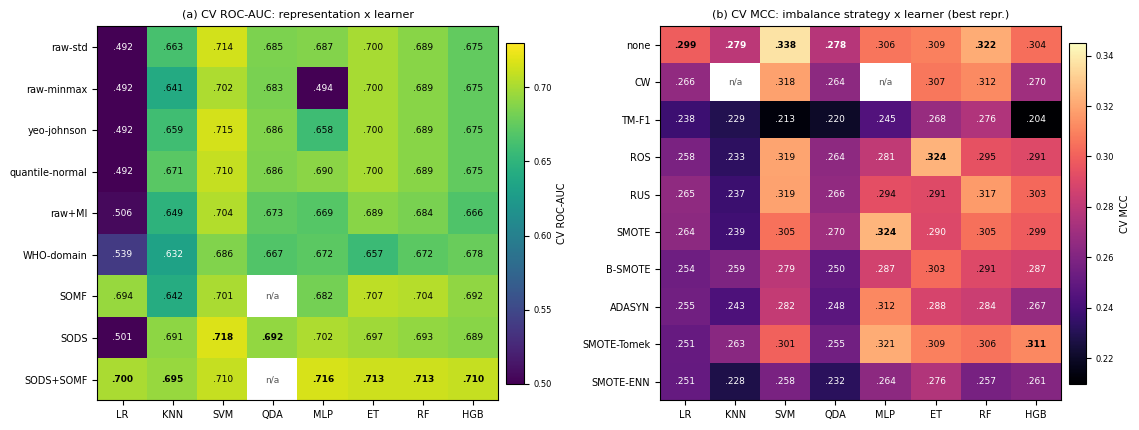

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
panels = [(axes[0], sk_repr_auc, "viridis", (0.5, 0.73), "CV ROC-AUC", "(a) CV ROC-AUC: representation x learner"),
          (axes[1], sk_imb_mcc, "magma", (0.21, 0.345), "CV MCC", "(b) CV MCC: imbalance strategy x learner (best repr.)")]
for ax, M, cmap, (lo, hi), label, title in panels:
    A = M.to_numpy(float)
    im = ax.imshow(A, cmap=cmap, vmin=lo, vmax=hi, aspect="auto")
    best_cell = np.nanargmax(A, axis=0)
    for i in range(A.shape[0]):
        for j in range(A.shape[1]):
            txt = "n/a" if np.isnan(A[i, j]) else f"{A[i, j]:.3f}".lstrip("0")
            light = not np.isnan(A[i, j]) and (A[i, j] - lo) / (hi - lo) > 0.6
            color = "0.35" if np.isnan(A[i, j]) else "black" if light else "white"
            ax.text(j, i, txt, ha="center", va="center", fontsize=6.5, color=color,
                    fontweight="bold" if best_cell[j] == i else "normal")
    ax.set_xticks(range(A.shape[1]))
    ax.set_xticklabels(M.columns, fontsize=7)
    ax.set_yticks(range(A.shape[0]))
    ax.set_yticklabels(M.index, fontsize=7)
    ax.set_title(title, fontsize=8)
    cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
    cb.set_label(label, fontsize=7)
    cb.ax.tick_params(labelsize=6)
fig.tight_layout()
fig.savefig(f"{OUT}/screening_heatmaps.png", dpi=300, bbox_inches="tight")
fig.savefig(f"{OUT}/screening_heatmaps.pdf", bbox_inches="tight")
plt.show()

### Boosting libraries: representations
The same screen for XGBoost, LightGBM and CatBoost, with Extra Trees as a reference.

In [17]:
folds1 = cv_folds(Xtr, ytr, reps=1)
rows = []
for lib in NEW_LIBS + ["ET"]:
    for rep in REPRS:
        t = time.time()
        r = cv_evaluate(build_pipeline(lib, rep, "none"), Xtr, ytr, folds1, f"{lib}|{rep}")
        rows.append(dict(learner=lib, repr=rep, auc=r.auc.mean(), acc=r.acc.mean(), mcc=r.mcc.mean(),
                         f1=r.f1.mean(), secs=time.time() - t))
        print(f"  {lib:9s} {rep:11s} AUC {rows[-1]['auc']:.3f}  acc {rows[-1]['acc']:.3f}  "
              f"({rows[-1]['secs']:.0f}s)")
screen_repr = pd.DataFrame(rows)
screen_repr.to_csv(f"{OUT}/kaggle_screen_repr.csv", index=False)
print(screen_repr.pivot(index="repr", columns="learner", values="auc").loc[REPRS].round(3).to_string())

print("\nCV ROC-AUC from the raw features to the best second-order representation")
for lib in NEW_LIBS + ["ET"]:
    s = screen_repr[screen_repr.learner == lib].set_index("repr").auc
    best2 = s.drop("raw-std").idxmax()
    print(f"  {lib:9s} raw {s['raw-std']:.3f} -> {best2} {s[best2]:.3f} (change {s[best2] - s['raw-std']:+.3f})")

  XGBoost   raw-std     AUC 0.679  acc 0.663  (3s)
  XGBoost   SOMF        AUC 0.691  acc 0.657  (9s)
  XGBoost   SODS        AUC 0.682  acc 0.659  (2s)
  XGBoost   SODS+SOMF   AUC 0.714  acc 0.678  (4s)
  LightGBM  raw-std     AUC 0.668  acc 0.658  (3s)
  LightGBM  SOMF        AUC 0.699  acc 0.663  (7s)
  LightGBM  SODS        AUC 0.672  acc 0.652  (3s)
  LightGBM  SODS+SOMF   AUC 0.706  acc 0.669  (4s)
  CatBoost  raw-std     AUC 0.691  acc 0.667  (9s)
  CatBoost  SOMF        AUC 0.695  acc 0.672  (24s)
  CatBoost  SODS        AUC 0.704  acc 0.677  (7s)
  CatBoost  SODS+SOMF   AUC 0.724  acc 0.677  (13s)
  ET        raw-std     AUC 0.690  acc 0.661  (7s)
  ET        SOMF        AUC 0.717  acc 0.681  (8s)
  ET        SODS        AUC 0.673  acc 0.611  (7s)
  ET        SODS+SOMF   AUC 0.725  acc 0.689  (7s)
learner    CatBoost     ET  LightGBM  XGBoost
repr                                         
raw-std       0.691  0.690     0.668    0.679
SOMF          0.695  0.717     0.699    0.69

### Boosting libraries: imbalance strategies
The ten strategies on each library's representation.

In [18]:
STRATEGIES = ["none", "CW", "TM-F1", "ROS", "RUS", "SMOTE", "B-SMOTE", "ADASYN", "SMOTE-Tomek", "SMOTE-ENN"]
screen_best_repr = {lib: screen_repr[screen_repr.learner == lib].sort_values("auc").iloc[-1]["repr"]
                    for lib in screen_repr.learner.unique()}
best_repr = dict(screen_best_repr)
if FIXED_CONFIG:
    best_repr.update({lib: FIXED_CFG[lib][0] for lib in NEW_LIBS})
for lib in NEW_LIBS:
    print(f"  {lib}: screen picks {screen_best_repr[lib]}, fixed setting {FIXED_CFG[lib][0]}, "
          f"used here: {best_repr[lib]}")

rows = []
for lib in NEW_LIBS:
    for st in STRATEGIES:
        t = time.time()
        try:
            pipe = build_pipeline(lib, best_repr[lib], st)
        except NotApplicable:
            rows.append(dict(learner=lib, strategy=st, repr=best_repr[lib]))
            print(f"  {lib:9s} {st:12s} n/a")
            continue
        r = cv_evaluate(pipe, Xtr, ytr, folds1, f"{lib}|{st}")
        rows.append(dict(learner=lib, strategy=st, repr=best_repr[lib], auc=r.auc.mean(), acc=r.acc.mean(),
                         rec=r.rec.mean(), f1=r.f1.mean(), mcc=r.mcc.mean(), secs=time.time() - t))
        print(f"  {lib:9s} {st:12s} AUC {rows[-1]['auc']:.3f} acc {rows[-1]['acc']:.3f} "
              f"rec {rows[-1]['rec']:.3f} MCC {rows[-1]['mcc']:.3f} ({rows[-1]['secs']:.0f}s)")
screen_imb = pd.DataFrame(rows, columns=["learner", "strategy", "repr", "auc", "acc", "rec", "f1", "mcc", "secs"])
screen_imb.to_csv(f"{OUT}/kaggle_screen_imbalance.csv", index=False)

if len(screen_imb):
    print("\nchange against 'none', over the other strategies")
    for lib in NEW_LIBS:
        s = screen_imb[screen_imb.learner == lib].set_index("strategy").dropna(subset=["auc"])
        d_auc = (s.auc - s.loc["none", "auc"]).drop("none")
        d_rec = (s.rec - s.loc["none", "rec"]).drop("none")
        print(f"  {lib:9s} ROC-AUC {d_auc.min():+.3f} to {d_auc.max():+.3f} | "
              f"recall {d_rec.min():+.3f} to {d_rec.max():+.3f}")

  XGBoost: screen picks SODS+SOMF, fixed setting SODS+SOMF, used here: SODS+SOMF
  LightGBM: screen picks SODS+SOMF, fixed setting SODS+SOMF, used here: SODS+SOMF
  CatBoost: screen picks SODS+SOMF, fixed setting SODS+SOMF, used here: SODS+SOMF
  XGBoost   none         AUC 0.714 acc 0.678 rec 0.464 MCC 0.299 (4s)
  XGBoost   CW           AUC 0.712 acc 0.672 rec 0.542 MCC 0.302 (4s)
  XGBoost   TM-F1        AUC 0.714 acc 0.557 rec 0.857 MCC 0.243 (16s)
  XGBoost   ROS          AUC 0.712 acc 0.658 rec 0.507 MCC 0.269 (4s)
  XGBoost   RUS          AUC 0.706 acc 0.645 rec 0.620 MCC 0.276 (4s)
  XGBoost   SMOTE        AUC 0.715 acc 0.673 rec 0.551 MCC 0.306 (4s)
  XGBoost   B-SMOTE      AUC 0.705 acc 0.655 rec 0.541 MCC 0.272 (4s)
  XGBoost   ADASYN       AUC 0.703 acc 0.657 rec 0.551 MCC 0.277 (4s)
  XGBoost   SMOTE-Tomek  AUC 0.715 acc 0.672 rec 0.545 MCC 0.303 (5s)
  XGBoost   SMOTE-ENN    AUC 0.696 acc 0.629 rec 0.647 MCC 0.258 (4s)
  LightGBM  none         AUC 0.706 acc 0.669 rec 0.472

# D. Tuning and the locked hold-out
Logistic regression, the RBF-SVM, Extra Trees, random forest and GBDT keep the tuned settings of the model zoo. kNN, QDA, the MLP and the boosting libraries are tuned here by randomized search with inner 5-fold CV on ROC-AUC. With `FIXED_CONFIG = True` each learner uses the representation and imbalance setting in `FIXED_CFG`; with `False` both come from the screens.

In [19]:
SPACES = {
    "XGBoost": {"clf__n_estimators": [200, 400, 800], "clf__max_depth": [3, 4, 5, 6, 8],
                "clf__learning_rate": [0.02, 0.05, 0.1], "clf__subsample": [0.7, 0.85, 1.0],
                "clf__colsample_bytree": [0.6, 0.8, 1.0], "clf__reg_lambda": [0.5, 1.0, 5.0],
                "clf__min_child_weight": [1, 5, 10]},
    "LightGBM": {"clf__n_estimators": [200, 400, 800], "clf__num_leaves": [15, 31, 63],
                 "clf__learning_rate": [0.02, 0.05, 0.1], "clf__min_child_samples": [10, 20, 40],
                 "clf__subsample": [0.7, 0.85, 1.0], "clf__colsample_bytree": [0.6, 0.8, 1.0]},
    "CatBoost": {"clf__iterations": [300, 600, 1000], "clf__depth": [4, 6, 8],
                 "clf__learning_rate": [0.02, 0.05, 0.1], "clf__l2_leaf_reg": [1.0, 3.0, 9.0]},
}
tuned_params, tuned_cv = {}, []
folds2 = cv_folds(Xtr, ytr)
for lib in NEW_LIBS:
    s = screen_imb[screen_imb.learner == lib].dropna(subset=["mcc"])
    screen_st = s.sort_values("mcc").iloc[-1]["strategy"] if len(s) else "none"
    rep, st = FIXED_CFG[lib] if FIXED_CONFIG else (best_repr[lib], screen_st)
    print(f"  {lib}: screens pick {screen_best_repr[lib]} / {screen_st}; fixed setting "
          f"{' / '.join(FIXED_CFG[lib])}; used: {rep} / {st}")
    base = build_pipeline(lib, rep, "none")
    t = time.time()
    rs = RandomizedSearchCV(base, SPACES[lib], n_iter=N_ITER_TUNE, scoring="roc_auc", refit=False,
                            cv=StratifiedKFold(5, shuffle=True, random_state=7), random_state=0,
                            n_jobs=1).fit(Xtr, ytr)
    tuned_params[lib] = dict(repr=rep, strategy=st,
                             params={k.replace("clf__", ""): v for k, v in rs.best_params_.items()},
                             inner_auc=float(rs.best_score_))
    print(f"  {lib}: inner AUC {rs.best_score_:.4f} in {time.time() - t:.0f}s -> {tuned_params[lib]['params']}")
    pipe = build_pipeline(lib, rep, st)
    clf = pipe.named_steps["clf"]
    target = clf.estimator if hasattr(clf, "estimator") else clf
    target.set_params(**tuned_params[lib]["params"])
    tuned_cv.append(cv_evaluate(pipe, Xtr, ytr, folds2, f"{lib} (tuned)"))
tuned_cv = pd.concat(tuned_cv) if tuned_cv else pd.DataFrame()
with open(f"{OUT}/kaggle_tuned_params.json", "w") as fh:
    json.dump(tuned_params, fh, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
if len(tuned_cv):
    print(tuned_cv.groupby("model")[["acc", "f1", "mcc", "auc"]].mean().round(3).to_string())

  XGBoost: screens pick SODS+SOMF / SMOTE; fixed setting SODS+SOMF / SMOTE-Tomek; used: SODS+SOMF / SMOTE-Tomek
  XGBoost: inner AUC 0.7169 in 73s -> {'subsample': 0.7, 'reg_lambda': 5.0, 'n_estimators': 400, 'min_child_weight': 1, 'max_depth': 5, 'learning_rate': 0.02, 'colsample_bytree': 1.0}
  LightGBM: screens pick SODS+SOMF / SMOTE-Tomek; fixed setting SODS+SOMF / SMOTE-Tomek; used: SODS+SOMF / SMOTE-Tomek
  LightGBM: inner AUC 0.7149 in 106s -> {'subsample': 0.7, 'num_leaves': 15, 'n_estimators': 400, 'min_child_samples': 20, 'learning_rate': 0.02, 'colsample_bytree': 1.0}
  CatBoost: screens pick SODS+SOMF / RUS; fixed setting SODS+SOMF / RUS; used: SODS+SOMF / RUS
  CatBoost: inner AUC 0.7276 in 586s -> {'learning_rate': 0.02, 'l2_leaf_reg': 9.0, 'iterations': 600, 'depth': 6}
                    acc     f1    mcc    auc
model                                       
CatBoost (tuned)  0.661  0.587  0.303  0.722
LightGBM (tuned)  0.664  0.566  0.292  0.713
XGBoost (tuned)   0.673 

In [20]:
SK_SPACES = {
    "KNN": {"clf__n_neighbors": [15, 25, 35, 51, 75], "clf__weights": ["uniform", "distance"], "clf__p": [1, 2]},
    "QDA": {"clf__reg_param": [0.0, 1e-3, 1e-2, 0.05, 0.1, 0.2, 0.3]},
    "MLP": {"clf__hidden_layer_sizes": [(32,), (64,), (64, 32), (100,)], "clf__alpha": [1e-4, 1e-3, 1e-2, 0.1],
            "clf__learning_rate_init": [1e-3, 3e-3]},
}
for lrn, space in SK_SPACES.items():
    s = sk_imb_screen[sk_imb_screen.learner == lrn].dropna(subset=["mcc"])
    screen_st = s.sort_values("mcc").iloc[-1]["strategy"]
    rep, st = FIXED_CFG[lrn] if FIXED_CONFIG else (screen_best[lrn], screen_st)
    print(f"  {lrn}: screens pick {screen_best[lrn]} / {screen_st}; fixed setting "
          f"{' / '.join(FIXED_CFG[lrn])}; used: {rep} / {st}")
    n_iter = int(min(N_ITER_TUNE, np.prod([len(v) for v in space.values()])))
    t = time.time()
    rs = RandomizedSearchCV(build_pipeline(lrn, rep, "none"), space, n_iter=n_iter, scoring="roc_auc", refit=False,
                            cv=StratifiedKFold(5, shuffle=True, random_state=7), random_state=0,
                            n_jobs=1).fit(Xtr, ytr)
    tuned_params[lrn] = dict(repr=rep, strategy=st,
                             params={k.replace("clf__", ""): v for k, v in rs.best_params_.items()},
                             inner_auc=float(rs.best_score_))
    print(f"  {lrn}: inner AUC {rs.best_score_:.4f} in {time.time() - t:.0f}s -> {tuned_params[lrn]['params']}")
with open(f"{OUT}/kaggle_tuned_params.json", "w") as fh:
    json.dump(tuned_params, fh, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))

  KNN: screens pick SODS+SOMF / none; fixed setting SODS+SOMF / none; used: SODS+SOMF / none
  KNN: inner AUC 0.6991 in 5s -> {'weights': 'distance', 'p': 2, 'n_neighbors': 51}
  QDA: screens pick SODS / none; fixed setting SODS / SMOTE-Tomek; used: SODS / SMOTE-Tomek
  QDA: inner AUC 0.6902 in 1s -> {'reg_param': 0.0}
  MLP: screens pick SODS+SOMF / SMOTE; fixed setting SODS+SOMF / SMOTE-Tomek; used: SODS+SOMF / SMOTE-Tomek
  MLP: inner AUC 0.7363 in 35s -> {'learning_rate_init': 0.003, 'hidden_layer_sizes': (64, 32), 'alpha': 0.1}


### Candidates on the locked hold-out
Each candidate gets 5×2 CV on the training partition and a single evaluation on the 656-sample hold-out. The selection rule (highest CV MCC, ties within 0.005 broken by CV AUC) runs over the scikit-learn candidates. DeLong and McNemar tests compare the candidates with the reference stack, with Holm-adjusted p-values.

In [21]:
STACK_REPR = {"SVM": "SODS", "ET": "SODS+SOMF", "GBDT-sk": "SODS+SOMF", "LR": "SODS+SOMF",
             "RF": "SODS+SOMF", "MQDA": "SODS"}       # representation per stack member

def tuned_pipe(lib, strategy=None):
    cfg = tuned_params.get(lib, dict(repr=STACK_REPR.get(lib, best_repr.get(lib, "SODS+SOMF")),
                                     strategy="none", params={}))
    p = build_pipeline(lib, cfg["repr"], strategy if strategy is not None else cfg["strategy"])
    clf = p.named_steps["clf"]
    target = clf.estimator if hasattr(clf, "estimator") else clf
    if cfg["params"]:
        target.set_params(**cfg["params"])
    return p

def stack_of(names, meta_weighted=False):
    est = [(n.lower(), tuned_pipe(n, "none")) for n in names]
    meta = LogisticRegression(max_iter=2000, class_weight="balanced" if meta_weighted else None)
    return StackingClassifier(est, final_estimator=meta, cv=3, n_jobs=1, passthrough=False)

SHORT_LIB = {"XGBoost": "XGB", "LightGBM": "LGBM", "CatBoost": "CatBoost"}
REF = "Stack (SVM, ET, GBDT, LR)"            # reference stack
BASELINE = "Conventional leak-free pipeline"
MAIN_SINGLES = {"Logistic regression": "LR", "kNN": "KNN", "RBF-SVM": "SVM", "QDA": "QDA", "MLP": "MLP",
                "Extra Trees": "ET", "Random forest": "RF", "GBDT": "GBDT-sk"}
CANDIDATES = {name: tuned_pipe(lrn) for name, lrn in MAIN_SINGLES.items()}
for lib in NEW_LIBS:
    CANDIDATES[f"{lib} (tuned)"] = tuned_pipe(lib)
CANDIDATES["Soft vote (SVM, ET, GBDT)"] = VotingClassifier(
    [(n.lower(), tuned_pipe(n, "none")) for n in ["SVM", "ET", "GBDT-sk"]], voting="soft")
CANDIDATES[REF] = stack_of(["SVM", "ET", "GBDT-sk", "LR"])
CANDIDATES["G–D stack"] = stack_of(["MQDA", "SVM", "ET", "GBDT-sk", "LR"])
CANDIDATES["G–D stack, weighted meta"] = stack_of(["MQDA", "SVM", "ET", "GBDT-sk", "LR"], meta_weighted=True)
if "CatBoost" in NEW_LIBS:
    CANDIDATES["Stack (SVM, ET, CatBoost, LR)"] = stack_of(["SVM", "ET", "CatBoost", "LR"])
if len(NEW_LIBS) >= 2:
    CANDIDATES["Stack (SVM, ET, " + ", ".join(SHORT_LIB[l] for l in NEW_LIBS) + ", LR)"] = \
        stack_of(["SVM", "ET"] + NEW_LIBS + ["LR"])
if "CatBoost" in NEW_LIBS:
    CANDIDATES["G–D stack, CatBoost"] = stack_of(["MQDA", "SVM", "ET", "CatBoost", "LR"])
    CANDIDATES["Soft vote (SVM, ET, CatBoost)"] = VotingClassifier(
        [(n.lower(), tuned_pipe(n, "none")) for n in ["SVM", "ET", "CatBoost"]], voting="soft")
CANDIDATES[BASELINE] = Pipeline([
    ("imp", SimpleImputer(strategy="median")), ("sc", MinMaxScaler()),
    ("clf", ResampledClassifier(HistGradientBoostingClassifier(random_state=SEED), "ADASYN", SEED))])
CANDIDATES["RBF-SVM, raw"] = Pipeline([("imp", SimpleImputer(strategy="mean")), ("sc", StandardScaler()),   # Obulezi et al.
                                       ("clf", SVC(probability=True, random_state=SEED))])
MAIN_CANDIDATES = list(MAIN_SINGLES) + ["Soft vote (SVM, ET, GBDT)", REF, "G–D stack", "G–D stack, weighted meta",
                                        BASELINE, "RBF-SVM, raw"]

cv_rows, hold_rows, preds, fitted = [], [], {}, {}
for name, est in CANDIDATES.items():
    t = time.time()
    r = cv_evaluate(est, Xtr, ytr, folds2, name)
    cv_rows.append(r)
    fit = clone(est).fit(Xtr, ytr)
    fitted[name] = fit
    s = scores_of(fit, Xte)
    yh = fit.predict(Xte)
    preds[name] = (yh, s)
    m = all_metrics(yte, yh, s)
    lo, hi = wilson_ci(int((yh == yte).sum()), len(yte))
    alo, ahi = bootstrap_ci(yte, yh, s, "auc")
    flo, fhi = bootstrap_ci(yte, yh, s, "f1")
    mlo, mhi = bootstrap_ci(yte, yh, s, "mcc")
    m.update(model=name, acc_lo=lo, acc_hi=hi, auc_lo=alo, auc_hi=ahi, f1_lo=flo, f1_hi=fhi, mcc_lo=mlo,
             mcc_hi=mhi, cv_auc=r.auc.mean(), cv_mcc=r.mcc.mean(), secs=time.time() - t)
    hold_rows.append(m)
    print(f"  {name:42s} CV AUC {r.auc.mean():.3f} MCC {r.mcc.mean():.3f} | hold-out acc {m['acc']:.3f} "
          f"AUC {m['auc']:.3f} ({m['secs']:.0f}s)")
cv_all = pd.concat(cv_rows)
hold = pd.DataFrame(hold_rows).set_index("model")
cv_all.to_csv(f"{OUT}/kaggle_cv_folds.csv", index=False)
hold.to_csv(f"{OUT}/kaggle_holdout_results.csv")
scores = pd.DataFrame({"y_true": yte})
for name, (yh, s) in preds.items():
    scores[f"{name} | score"] = s
    scores[f"{name} | label"] = yh
scores.to_csv(f"{OUT}/kaggle_holdout_scores.csv", index=False)

# selection rule: top CV MCC, ties within 0.005 broken by CV AUC
TIE = 0.005
def select(names):
    h = hold.loc[names]
    pool = h[h.cv_mcc >= h.cv_mcc.max() - TIE]
    return pool.cv_auc.idxmax(), list(pool.index)
best, pool = select(MAIN_CANDIDATES)
best_single, _ = select(list(MAIN_SINGLES))
print(f"\nthe selection rule picks: {best} (within {TIE} of the top CV MCC: {', '.join(pool)})")
print(f"best single model by the same rule: {best_single}")
SELECTED = REF if FIXED_CONFIG else best        # model analysed in the tests below and in Part E
print(f"analysed below as the selected model: {SELECTED}")

n_tr, n_te = len(folds2[0][0]), len(folds2[0][1])

def paired_tests(a_name, b_name):
    a = cv_all[cv_all.model == a_name].sort_values("fold")
    b = cv_all[cv_all.model == b_name].sort_values("fold")
    _, p_auc = corrected_resampled_ttest(a.auc.values, b.auc.values, n_tr, n_te)
    _, p_mcc = corrected_resampled_ttest(a.mcc.values, b.mcc.values, n_tr, n_te)
    A, B, z, p_del = delong_test(yte, preds[a_name][1], preds[b_name][1])
    nb, nc, p_mcn = mcnemar_test(yte, preds[a_name][0], preds[b_name][0])
    return dict(reference=a_name, other=b_name, auc_reference=A, auc_other=B, delong_z=z, delong_p=p_del,
                mcnemar_b=nb, mcnemar_c=nc, mcnemar_p=p_mcn, cv_auc_p=p_auc, cv_mcc_p=p_mcc)

tests_ref = pd.DataFrame([paired_tests(REF, o) for o in hold.index if o != REF])
tests_best = pd.DataFrame([paired_tests(best, o) for o in hold.index if o != best])
confirm = [m for m in [BASELINE, "RBF-SVM, raw", best_single] if m != SELECTED]
tests_main = pd.DataFrame([paired_tests(SELECTED, o) for o in dict.fromkeys(confirm)])
for t in (tests_ref, tests_best, tests_main):   # Holm correction across the comparisons of each table
    for col in ["delong_p", "mcnemar_p", "cv_auc_p", "cv_mcc_p"]:
        t[col + "_holm"] = holm(t[col])
tests_ref.to_csv(f"{OUT}/kaggle_tests_vs_stack.csv", index=False)
tests_best.to_csv(f"{OUT}/kaggle_tests_vs_selected.csv", index=False)
tests_main.to_csv(f"{OUT}/tests_selected_model.csv", index=False)
cols = ["other", "auc_reference", "auc_other", "delong_p", "delong_p_holm", "mcnemar_b", "mcnemar_c", "mcnemar_p",
        "mcnemar_p_holm", "cv_auc_p", "cv_auc_p_holm", "cv_mcc_p", "cv_mcc_p_holm"]
print(f"\nTests of {SELECTED} against the baselines and the best single model (Holm over {len(tests_main)})")
print(tests_main[cols].round(4).to_string(index=False))
print(f"\nAll candidates against {REF} (Holm over all {len(tests_ref)} comparisons)")
print(tests_ref[cols].round(4).to_string(index=False))

  Logistic regression                        CV AUC 0.701 MCC 0.290 | hold-out acc 0.681 AUC 0.698 (10s)
  kNN                                        CV AUC 0.699 MCC 0.279 | hold-out acc 0.675 AUC 0.696 (10s)
  RBF-SVM                                    CV AUC 0.722 MCC 0.321 | hold-out acc 0.684 AUC 0.687 (20s)
  QDA                                        CV AUC 0.691 MCC 0.259 | hold-out acc 0.684 AUC 0.693 (10s)
  MLP                                        CV AUC 0.726 MCC 0.300 | hold-out acc 0.657 AUC 0.696 (14s)
  Extra Trees                                CV AUC 0.725 MCC 0.312 | hold-out acc 0.683 AUC 0.713 (24s)
  Random forest                              CV AUC 0.708 MCC 0.306 | hold-out acc 0.669 AUC 0.692 (52s)
  GBDT                                       CV AUC 0.711 MCC 0.313 | hold-out acc 0.655 AUC 0.687 (28s)
  XGBoost (tuned)                            CV AUC 0.717 MCC 0.311 | hold-out acc 0.659 AUC 0.690 (21s)
  LightGBM (tuned)                           CV AUC 0.7

# E. Evaluation of the selected model
Hold-out ROC curves, 20 Monte-Carlo re-splits of all 3,276 rows (`split_montecarlo_20.csv`) with paired tests, learning curves, a label-permutation test and permutation importance.

In [22]:
mc_models = list(dict.fromkeys([SELECTED, best_single, "RBF-SVM, raw", BASELINE]))
mc_rows = []
for split in range(N_MC):
    a, b = train_test_split(np.arange(len(y_all)), test_size=0.2, stratify=y_all, random_state=1000 + split)
    for name in mc_models:
        est = clone(CANDIDATES[name]).fit(X_all[a], y_all[a])
        s = scores_of(est, X_all[b])
        m = all_metrics(y_all[b], est.predict(X_all[b]), s)
        m.update(model=name, split=split)
        mc_rows.append(m)
    print(f"  Monte-Carlo split {split} done")
mc = pd.DataFrame(mc_rows)
mc.to_csv(f"{OUT}/kaggle_mc_splits.csv", index=False)
print(mc.groupby("model")[["acc", "auc", "mcc"]].agg(["mean", "std"]).round(3).to_string())
w = mc.pivot(index="split", columns="model", values="auc")
for name in mc_models:
    if name != BASELINE:
        print(f"  {name}: higher ROC-AUC than the conventional pipeline in "
              f"{int((w[name] > w[BASELINE]).sum())} of {N_MC} splits")

# Paired results: selected model minus each other model, same splits
rows = []
for other in [m for m in mc_models if m != SELECTED]:
    for metric in ["auc", "acc"]:
        p = mc.pivot(index="split", columns="model", values=metric)
        diff = p[SELECTED] - p[other]
        _, p_t = corrected_resampled_ttest(p[SELECTED].values, p[other].values, len(a), len(b))
        rows.append(dict(reference=SELECTED, other=other, metric=metric, mean_diff=diff.mean(), sd_diff=diff.std(ddof=1),
                         wins=int((diff > 0).sum()), ties=int((diff == 0).sum()), splits=len(diff), corrected_t_p=p_t))
mc_paired = pd.DataFrame(rows)
mc_paired["corrected_t_p_holm"] = holm(mc_paired.corrected_t_p)
mc_paired.to_csv(f"{OUT}/kaggle_mc_paired.csv", index=False)
print("\nPaired differences over the splits (corrected resampled t-test, Holm-adjusted)")
print(mc_paired.drop(columns="reference").round(4).to_string(index=False))

  Monte-Carlo split 0 done
  Monte-Carlo split 1 done
  Monte-Carlo split 2 done
  Monte-Carlo split 3 done
  Monte-Carlo split 4 done
  Monte-Carlo split 5 done
  Monte-Carlo split 6 done
  Monte-Carlo split 7 done
  Monte-Carlo split 8 done
  Monte-Carlo split 9 done
  Monte-Carlo split 10 done
  Monte-Carlo split 11 done
  Monte-Carlo split 12 done
  Monte-Carlo split 13 done
  Monte-Carlo split 14 done
  Monte-Carlo split 15 done
  Monte-Carlo split 16 done
  Monte-Carlo split 17 done
  Monte-Carlo split 18 done
  Monte-Carlo split 19 done
                                   acc           auc           mcc       
                                  mean    std   mean    std   mean    std
model                                                                    
Conventional leak-free pipeline  0.617  0.018  0.665  0.019  0.206  0.038
RBF-SVM                          0.690  0.017  0.714  0.022  0.320  0.046
RBF-SVM, raw                     0.679  0.017  0.691  0.022  0.290  0.046
Stack 

                          model  n_train  auc_mean  auc_sd
      Stack (SVM, ET, GBDT, LR)      209     0.581   0.053
      Stack (SVM, ET, GBDT, LR)      681     0.683   0.024
      Stack (SVM, ET, GBDT, LR)     1152     0.716   0.016
      Stack (SVM, ET, GBDT, LR)     1624     0.730   0.014
      Stack (SVM, ET, GBDT, LR)     2096     0.737   0.017
Conventional leak-free pipeline      209     0.559   0.031
Conventional leak-free pipeline      681     0.625   0.029
Conventional leak-free pipeline     1152     0.654   0.013
Conventional leak-free pipeline     1624     0.669   0.011
Conventional leak-free pipeline     2096     0.671   0.009


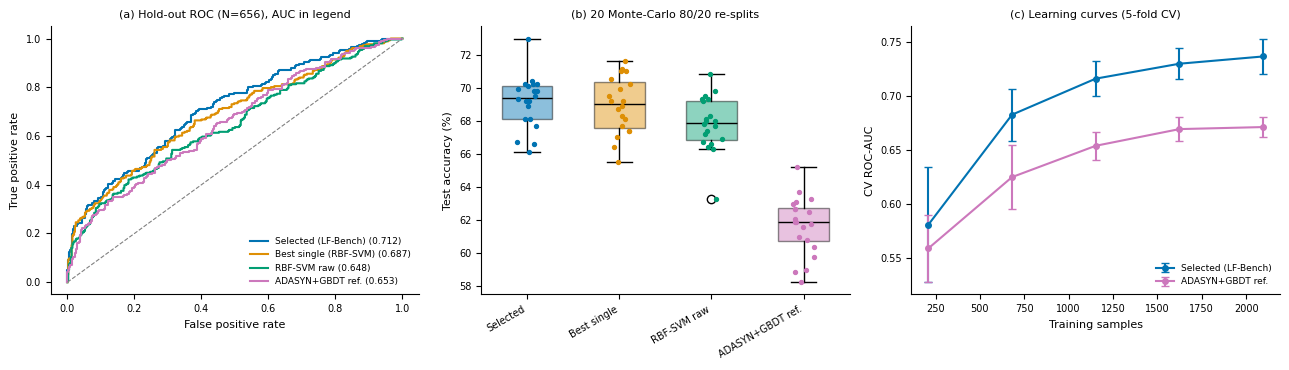

In [23]:
from sklearn.model_selection import learning_curve

lc_rows = []
for name in [SELECTED, BASELINE]:
    sizes, _, te_sc = learning_curve(CANDIDATES[name], Xtr, ytr, train_sizes=np.linspace(0.1, 1.0, 5), cv=folds1,
                                     scoring="roc_auc", n_jobs=1, shuffle=False)
    lc_rows += [dict(model=name, n_train=int(n), auc_mean=m, auc_sd=sd)
                for n, m, sd in zip(sizes, te_sc.mean(1), te_sc.std(1))]
learning = pd.DataFrame(lc_rows)
learning.to_csv(f"{OUT}/learning_curves.csv", index=False)
print(learning.round(3).to_string(index=False))

EVAL_NAMES = {SELECTED: "Selected (LF-Bench)", best_single: f"Best single ({best_single})",
              "RBF-SVM, raw": "RBF-SVM raw", BASELINE: "ADASYN+GBDT ref."}
EVAL_COLORS = ["#0173b2", "#de8f05", "#029e73", "#cc78bc"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
ax = axes[0]
for (name, label), col in zip(EVAL_NAMES.items(), EVAL_COLORS):
    fpr, tpr, _ = roc_curve(yte, preds[name][1])
    ax.plot(fpr, tpr, color=col, lw=1.5, label=f"{label} ({hold.loc[name, 'auc']:.3f})")
ax.plot([0, 1], [0, 1], ls="--", lw=0.8, color="0.5")
ax.set_xlabel("False positive rate", fontsize=8)
ax.set_ylabel("True positive rate", fontsize=8)
ax.set_title("(a) Hold-out ROC (N=656), AUC in legend", fontsize=8)
ax.legend(fontsize=6.5, frameon=False, loc="lower right")
ax = axes[1]
order = list(EVAL_NAMES)
data = [100 * mc[mc.model == m].acc.values for m in order]
bp = ax.boxplot(data, widths=0.55, patch_artist=True, medianprops=dict(color="black"))
for patch, col in zip(bp["boxes"], EVAL_COLORS):
    patch.set_facecolor(col)
    patch.set_alpha(0.45)
rng = np.random.RandomState(0)
for k, (vals, col) in enumerate(zip(data, EVAL_COLORS), start=1):
    ax.scatter(k + rng.uniform(-0.12, 0.12, len(vals)), vals, s=8, color=col, zorder=3)
ax.set_xticks(range(1, len(order) + 1))
ax.set_xticklabels([EVAL_NAMES[m].split(" (")[0] for m in order], rotation=30, ha="right", fontsize=7)
ax.set_ylabel("Test accuracy (%)", fontsize=8)
ax.set_title(f"(b) {N_MC} Monte-Carlo 80/20 re-splits", fontsize=8)
ax = axes[2]
for name, col in [(SELECTED, EVAL_COLORS[0]), (BASELINE, EVAL_COLORS[3])]:
    d = learning[learning.model == name]
    ax.errorbar(d.n_train, d.auc_mean, yerr=d.auc_sd, marker="o", ms=4, capsize=3, color=col, label=EVAL_NAMES[name])
ax.set_xlabel("Training samples", fontsize=8)
ax.set_ylabel("CV ROC-AUC", fontsize=8)
ax.set_title("(c) Learning curves (5-fold CV)", fontsize=8)
ax.legend(fontsize=6.5, frameon=False, loc="lower right")
for ax in axes:
    ax.tick_params(labelsize=7)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
fig.tight_layout()
fig.savefig(f"{OUT}/selected_model_evaluation.png", dpi=300, bbox_inches="tight")
fig.savefig(f"{OUT}/selected_model_evaluation.pdf", bbox_inches="tight")
plt.show()

In [24]:
# Permutation test: refit on permuted training labels, score on the hold-out
rng = np.random.RandomState(0)
observed = hold.loc[SELECTED, "auc"]
null_auc, t = [], time.time()
for i in range(N_PERM):
    est = clone(CANDIDATES[SELECTED]).fit(Xtr, rng.permutation(ytr))
    null_auc.append(roc_auc_score(yte, scores_of(est, Xte)))
null_auc = np.array(null_auc)
p_perm = (1 + int((null_auc >= observed).sum())) / (N_PERM + 1)
pd.DataFrame({"permutation": np.arange(N_PERM), "holdout_auc": null_auc}).to_csv(f"{OUT}/permutation_test.csv",
                                                                                   index=False)
print(f"observed hold-out ROC-AUC {observed:.3f}; permuted labels: mean {null_auc.mean():.3f}, "
      f"max {null_auc.max():.3f} ({N_PERM} permutations, {time.time() - t:.0f}s)")
print(f"permutation p = {p_perm:.4f}; the smallest p possible with {N_PERM} permutations is {1 / (N_PERM + 1):.4f}")

observed hold-out ROC-AUC 0.712; permuted labels: mean 0.498, max 0.571 (100 permutations, 1605s)
permutation p = 0.0099; the smallest p possible with 100 permutations is 0.0099


In [25]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(fitted[SELECTED], Xte, yte, scoring="roc_auc", n_repeats=20, random_state=0, n_jobs=1)
importance = pd.DataFrame({"feature": FEATURES, "mean_auc_drop": pi.importances_mean,
                           "sd": pi.importances_std}).sort_values("mean_auc_drop", ascending=False)
importance.to_csv(f"{OUT}/permutation_importance.csv", index=False)
print(importance.round(4).to_string(index=False))
print("top three:", list(importance.feature[:3]), "| features kept by SODS:", SODS_KEPT)

        feature  mean_auc_drop     sd
             ph         0.1240 0.0201
        Sulfate         0.1141 0.0183
       Hardness         0.0733 0.0109
    Chloramines         0.0440 0.0087
         Solids         0.0437 0.0133
   Conductivity         0.0000 0.0000
 Organic_carbon         0.0000 0.0000
Trihalomethanes         0.0000 0.0000
      Turbidity         0.0000 0.0000
top three: ['ph', 'Sulfate', 'Hardness'] | features kept by SODS: ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate']


# F. Summary and export
Key numbers, LaTeX rows for the leakage, protocol and candidate tables, and a JSON summary of the run.

In [26]:
pd.set_option("display.width", 250)

def nl(x, d=3):
    if x is None or np.isnan(x):
        return "--"
    s_ = f"{x:.{d}f}"
    return s_[1:] if s_.startswith("0.") else s_.replace("-0.", "-.", 1)

leak_table = leakage_summary(leak)
m0 = leak[leak.mechanism == MECHANISMS[0]].groupby("model").acc.mean()
r, b, s = hold.loc[SELECTED], hold.loc[BASELINE], hold.loc["RBF-SVM, raw"]
mp = mc_paired[(mc_paired.other == BASELINE) & (mc_paired.metric == "auc")].iloc[0]
lc = learning[learning.model == SELECTED]

print("Key results")
print("  leak-free accuracy (M0): " + ", ".join(f"{k} {v:.3f}" for k, v in m0.items()))
print(f"  selection rule: {best}; best single model: {best_single}; analysed: {SELECTED}")
print(f"  {SELECTED} on the hold-out: acc {100 * r.acc:.1f}% [{100 * r.acc_lo:.1f}, {100 * r.acc_hi:.1f}], "
      f"MCC {r.mcc:.3f}, ROC-AUC {r.auc:.3f} [{r.auc_lo:.3f}, {r.auc_hi:.3f}], F1 {r.f1:.3f}")
print(f"  conventional pipeline: acc {100 * b.acc:.1f}%, ROC-AUC {b.auc:.3f}; raw RBF-SVM: acc {100 * s.acc:.1f}%, "
      f"ROC-AUC {s.auc:.3f}")
for _, t in tests_main.iterrows():
    print(f"  vs. {t.other}: DeLong p = {t.delong_p:.3g} (Holm {t.delong_p_holm:.3g}), McNemar p = {t.mcnemar_p:.3g} "
          f"(Holm {t.mcnemar_p_holm:.3g})")
print(f"  Monte-Carlo: mean ROC-AUC {mc[mc.model == SELECTED].auc.mean():.3f}, higher than the conventional pipeline "
      f"in {mp.wins} of {mp.splits} splits, corrected t-test p = {mp.corrected_t_p:.2g} (Holm {mp.corrected_t_p_holm:.2g})")
print(f"  learning curve: CV ROC-AUC {lc.auc_mean.iloc[-2]:.3f} at n = {lc.n_train.iloc[-2]}, "
      f"{lc.auc_mean.iloc[-1]:.3f} at n = {lc.n_train.iloc[-1]}")
print(f"  permutation test: p = {p_perm:.3f} ({N_PERM} permutations)")
print(f"  permutation importance, top three: {list(importance.feature[:3])}")
cat = "Stack (SVM, ET, CatBoost, LR)"
if cat in hold.index:
    rc, tc = hold.loc[cat], tests_ref.set_index("other").loc[cat]
    print(f"  CatBoost in place of GBDT: acc {100 * rc.acc:.1f}%, ROC-AUC {rc.auc:.3f}, DeLong p = {tc.delong_p:.2f} "
          f"(Holm {tc.delong_p_holm:.2f}) against {REF}")

# LaTeX rows
LEAK_LATEX = {"M0 leak-free (in-fold)": ("M0", "Leak-free (in-fold fitting)"),
              "M0b leak-free + in-fold SMOTE": ("M0b", "Leak-free + in-fold SMOTE"),
              "M1 global mean imputation": ("M1", "Global mean imp."),
              "M2 global imputation + scaling": ("M2", "Global imp. + scaling"),
              "M3 global SVR imputation": ("M3", "Global SVR imp."),
              "M3b label-aware SVR imputation": ("M3b", "Label-aware SVR imp."),
              "M4 class-mean imputation": ("M4", "Class-mean imp."),
              "M5 pre-split SMOTE": ("M5", "Pre-split SMOTE"),
              "M5b pre-split SMOTE, authentic test": ("M5b", "Pre-split SMOTE, auth. test"),
              "M6 pre-split ROS": ("M6", "Pre-split ROS"),
              "M7 scored rows in training": ("M7", "Scored rows in training")}
print("\n% ---- leakage attribution: RF acc & Boost. acc & RF AUC & Boost. AUC & RF acc leak / other ----")
for mech in MECHANISMS:
    row = leak_table.loc[mech]
    split = "--" if np.isnan(row["RF leak"]) else f"{nl(row['RF leak'])} / {nl(row['RF other'])}"
    print(f"{LEAK_LATEX[mech][0]} & {LEAK_LATEX[mech][1]} & {nl(row['RF acc'])} & {nl(row['Boost acc'])} & "
          f"{nl(row['RF AUC'])} & {nl(row['Boost AUC'])} & {split} \\\\")

print("\n% ---- protocol reconstructions: study & protocol & reported & this run ----")
for _, row in protocols.iterrows():
    print(f"{row.study} & {row.protocol.strip().replace('+ z', '+ $z$')} & {row.reported:.2f} & "
          f"{row['mean']:.1f} $\\pm$ {row.sd:.1f} \\\\")

def setting(name):
    lrn = MAIN_SINGLES.get(name, name.replace(" (tuned)", ""))
    if lrn in tuned_params:
        return f"{tuned_params[lrn]['repr']} / {tuned_params[lrn]['strategy'].replace('-', '--')}"
    if lrn in STACK_REPR:
        return f"{STACK_REPR[lrn]} / none"
    return {BASELINE: "min--max / ADASYN", "RBF-SVM, raw": "$z$-score / none"}.get(name, "mixed / --")

print("\n% ---- candidates: setting & CV AUC & CV MCC & acc [95% CI] & bal. acc & F1 & MCC & ROC-AUC [95% CI] ----")
for name, row in hold.iterrows():
    print(f"{name.replace('–', '--')} & {setting(name)} & {row.cv_auc:.3f} & {row.cv_mcc:.3f} & {row.acc:.3f} "
          f"[{row.acc_lo:.3f}, {row.acc_hi:.3f}] & {row.bacc:.3f} & {row.f1:.3f} & {row.mcc:.3f} & {row.auc:.3f} "
          f"[{row.auc_lo:.3f}, {row.auc_hi:.3f}] \\\\")

def _clean(o):
    if isinstance(o, dict):
        return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_clean(v) for v in o]
    if hasattr(o, "item"):
        o = o.item()
    if isinstance(o, float) and np.isnan(o):
        return None
    return o

T_COLS = ["cv_auc", "cv_mcc", "acc", "acc_lo", "acc_hi", "bacc", "f1", "mcc", "auc", "auc_lo", "auc_hi"]
summary = dict(versions=VERSIONS, quick=QUICK, fixed_config=FIXED_CONFIG, data_md5=DATA_MD5,
               boosting_libraries=NEW_LIBS, imblearn_used=HAS["imblearn"],
               leakage=leak_table.reset_index().to_dict("records"), protocols=protocols.to_dict("records"),
               screen_representations=sk_repr_screen.to_dict("records"),
               screen_imbalance=sk_imb_screen.to_dict("records"),
               imputers=imputer_screen.to_dict("records"), native_routes=native_auc,
               candidates=hold[T_COLS].reset_index().to_dict("records"),
               selected_by_rule=best, analysed=SELECTED, best_single=best_single, tuned_params=tuned_params,
               tests_selected_model=tests_main.to_dict("records"), tests_vs_stack=tests_ref.to_dict("records"),
               mc_paired=mc_paired.to_dict("records"), permutation_p=p_perm, n_permutations=N_PERM,
               permutation_importance=importance.to_dict("records"))
with open(f"{OUT}/kaggle_summary.json", "w") as fh:
    json.dump(_clean(summary), fh, indent=1)
print("\nfiles written:", ", ".join(sorted(os.path.basename(f) for f in glob.glob(f"{OUT}/*")
                                           if not f.endswith(".zip"))))

Key results
  leak-free accuracy (M0): CatBoost 0.671, LightGBM 0.652, RF 0.675, XGBoost 0.659
  selection rule: G–D stack; best single model: RBF-SVM; analysed: Stack (SVM, ET, GBDT, LR)
  Stack (SVM, ET, GBDT, LR) on the hold-out: acc 68.8% [65.1, 72.2], MCC 0.312, ROC-AUC 0.712 [0.671, 0.755], F1 0.462
  conventional pipeline: acc 61.0%, ROC-AUC 0.653; raw RBF-SVM: acc 66.8%, ROC-AUC 0.648
  vs. Conventional leak-free pipeline: DeLong p = 0.000944 (Holm 0.00189), McNemar p = 0.00017 (Holm 0.000509)
  vs. RBF-SVM, raw: DeLong p = 6.09e-05 (Holm 0.000183), McNemar p = 0.142 (Holm 0.284)
  vs. RBF-SVM: DeLong p = 0.0117 (Holm 0.0117), McNemar p = 0.856 (Holm 0.856)
  Monte-Carlo: mean ROC-AUC 0.727, higher than the conventional pipeline in 20 of 20 splits, corrected t-test p = 3.7e-05 (Holm 0.00018)
  learning curve: CV ROC-AUC 0.730 at n = 1624, 0.737 at n = 2096
  permutation test: p = 0.010 (100 permutations)
  permutation importance, top three: ['ph', 'Sulfate', 'Hardness']
  CatBo

In [27]:
# One zip with every output file, for download from the Output tab
import shutil
if os.path.exists(f"{OUT}/lf_bench_outputs.zip"):
    os.remove(f"{OUT}/lf_bench_outputs.zip")
shutil.move(shutil.make_archive("/tmp/lf_bench_outputs", "zip", OUT), f"{OUT}/lf_bench_outputs.zip")
print("download lf_bench_outputs.zip from the Output tab")

download lf_bench_outputs.zip from the Output tab
